# **Topicos de Datos y Texto** 
#### Profesor: Andres Eduardo Rangel Jimenez


### Analisis No Supervisado
### Analisis de Cluster

El término clustering hace referencia a un amplio abanico de técnicas cuya finalidad es encontrar patrones o grupos (clusters) dentro de un conjunto de observaciones. Las particiones se establecen de forma que, las observaciones que están dentro de un mismo grupo, son similares entre ellas y distintas a las observaciones de otros grupos. Se trata de un método de aprendizaje no supervisado (unsupervised), ya que el proceso no tiene en cuenta a qué grupo pertenece realmente cada observación (si es que existe tal información). Esta característica es la que diferencia al clustering de las métodos de clasificación en el que sí emplea la verdadera clasificación durante su entrenamiento.

Dada la utilidad del clustering en disciplinas muy distintas (genómica, marketing...), se han desarrollado multitud de variantes y adaptaciones de sus métodos y algoritmos. Pueden diferenciarse tres grupos principales:

- Partitioning Clustering: este tipo de algoritmos requieren que el usuario especifique de antemano el número de clusters que se van a crear (K-means, K-medoids).

- Hierarchical Clustering: este tipo de algoritmos no requieren que el usuario especifique de antemano el número de clusters. (agglomerative clustering, divisive clustering).

- DBSCAN

La librería Scikit Learn contiene implementaciones en Python de los principales algoritmos de clustering.

####  Medidas de distancia


Todos los métodos de clustering tienen una cosa en común, para llevar a cabo las agrupaciones necesitan definir y cuantificar la similitud entre las observaciones. El término distancia se emplea dentro del contexto del clustering como cuantificación de la similitud o diferencia entre observaciones. Si se representan las observaciones en un espacio  𝑝  dimensional, siendo  𝑝  el número de variables asociadas a cada observación, cuando más se asemejen dos observaciones más próximas estarán, de ahí que se emplee el término distancia. La característica que hace del clustering un método adaptable a escenarios muy diversos es que puede emplear casi cualquier tipo de distancia, lo que permite al investigador escoger la más adecuada para el estudio en cuestión. A continuación, se describen algunas de las más utilizadas.

#### La distancia euclidea

La distancia euclídea entre dos puntos $A(x_1, y_1, z_1)$ y  $B(x_2, y_2, z_2)$  es un espacio de dimension $n$ se define como:

##### Definición general en n dimensiones

$$
d(A,B) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}
$$

##### Caso en 2D

$A(x_1, y_1)$ y  $B(x_2, y_2)$

$$
d(A,B) = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2}
$$

##### Caso en 3D

$A(x_1, y_1, z_1)$ y  $B(x_2, y_2, z_2)$

$$
d(A,B) = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2 + (z_1 - z_2)^2}
$$

Una forma de dar mayor peso a aquellas observaciones que están más alejadas es emplear la distancia euclídea al cuadrado. En el caso del clustering, donde se busca agrupar observaciones que minimicen la distancia, esto se traduce en una mayor influencia de aquellas observaciones que están más distantes.

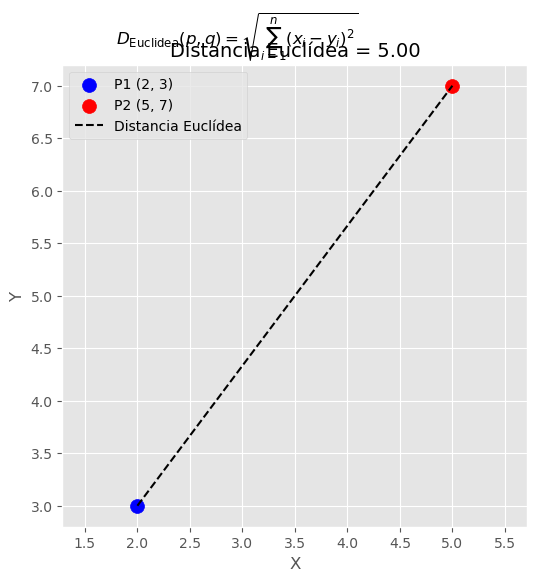

'distancia_euclidea.png'

In [181]:
import numpy as np
import matplotlib.pyplot as plt

# Definir dos puntos
p1 = np.array([2, 3])
p2 = np.array([5, 7])

# Calcular distancia Euclídea
distancia_euclidea = np.linalg.norm(p1 - p2)

# Crear gráfico listo para exportar
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*p1, color='blue', s=100, label=f'P1 {tuple(p1)}')
ax.scatter(*p2, color='red', s=100, label=f'P2 {tuple(p2)}')

# Dibujar la línea recta entre los puntos (distancia euclídea)
ax.plot([p1[0], p2[0]], [p1[1], p2[1]], 'k--', label="Distancia Euclídea")

# Personalización
ax.set_title(f"Distancia Euclídea = {distancia_euclidea:.2f}", fontsize=14)
ax.set_xlabel("X", fontsize=12)
ax.set_ylabel("Y", fontsize=12)
ax.legend()
ax.grid(True)
ax.axis("equal")

# Anotar fórmula LaTeX en el gráfico usando \sqrt
ax.text(1.8, 7.4, r"$D_{\mathrm{Euclidea}}(p, q) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}$", 
        fontsize=12, color="black")

# Guardar en alta resolución
output_path = "distancia_euclidea.png"
fig.savefig(output_path, dpi=300, bbox_inches='tight')

plt.show()
output_path

#### Distancia de Manhattan

La distancia de Manhattan, también conocida como taxicab metric, rectilinear distance o L1 distance, define la distancia entre dos puntos  𝑝  y  𝑞  como el sumatorio de las diferencias absolutas entre cada dimensión. Esta medida se ve menos afectada por outliers (es más robusta) que la distancia euclídea debido a que no eleva al cuadrado las diferencias.

La formula para dos puntos $p=(x_1,y_1)$ y $q=(x_2, y_2)$


$$
D_{\text{Manhattan}}(p, q) = \sum_{i=1}^{n} \left| x_i - y_i \right|
$$

La siguiente imagen muestra una comparación entre la distancia euclídea (segmento verde) y la distancia de manhattan (segmento rojo, amarillo y azul) en un espacio bidimensional. Existen múltiples caminos para unir dos puntos con una misma distancia de manhattan, pero solo uno con la distancia euclídea.

In [3]:
import numpy as np

# Definimos dos puntos
p1 = np.array([2, 3])
p2 = np.array([5, 7])

# Calculamos la distancia Manhattan
distancia_manhattan = np.sum(np.abs(p1 - p2))

print(f"Distancia Manhattan entre {p1} y {p2}: {distancia_manhattan}")

Distancia Manhattan entre [2 3] y [5 7]: 7


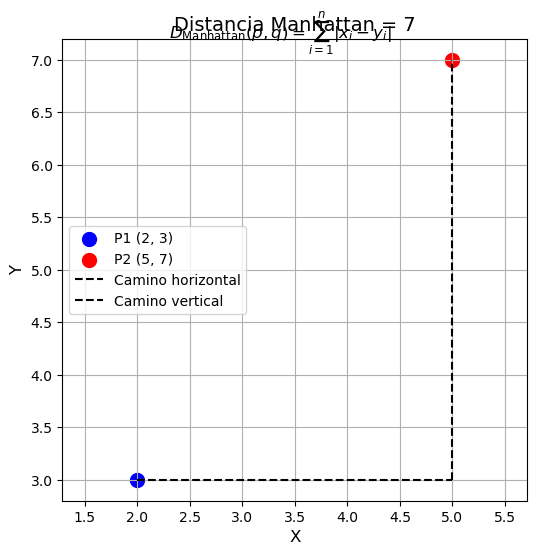

'distancia_manhattan.png'

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Definir dos puntos
p1 = np.array([2, 3])
p2 = np.array([5, 7])

# Calcular distancia Manhattan
distancia_manhattan = np.sum(np.abs(p1 - p2))

# Crear gráfico listo para exportar
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*p1, color='blue', s=100, label=f'P1 {tuple(p1)}')
ax.scatter(*p2, color='red', s=100, label=f'P2 {tuple(p2)}')

# Dibujar el "camino en L"
ax.plot([p1[0], p2[0]], [p1[1], p1[1]], 'k--', label="Camino horizontal")
ax.plot([p2[0], p2[0]], [p1[1], p2[1]], 'k--', label="Camino vertical")

# Personalización
ax.set_title(f"Distancia Manhattan = {distancia_manhattan}", fontsize=14)
ax.set_xlabel("X", fontsize=12)
ax.set_ylabel("Y", fontsize=12)
ax.legend()
ax.grid(True)
ax.axis("equal")

# Anotar fórmula LaTeX en el gráfico usando \mathrm
ax.text(2.3, 7.2, r"$D_{\mathrm{Manhattan}}(p, q) = \sum_{i=1}^{n} |x_i - y_i|$", 
        fontsize=12, color="black")

# Guardar en alta resolución
output_path = "distancia_manhattan.png"
fig.savefig(output_path, dpi=300, bbox_inches='tight')

plt.show()
output_path

#### Correlacion

La correlación es una medida de distancia muy útil cuando la definición de similitud se hace en términos de patrón o forma y no de desplazamiento o magnitud:

$$
d_{cor}(p,q)=1-correlacion(p,q)
$$

donde la correlación puede ser de distintos tipos (Pearson, Spearman, Kendall...). La correlacion de pearson: 

$
r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2 \sum_{i=1}^{n} (y_i - \bar{y})^2}}
$

En la siguiente imagen se muestra el perfil de 3 observaciones. a y b tienen exactamente el mismo patrón, pero b está desplazada 4 unidades por debajo de a. La observación c tiene un patrón distinto a las demás, pero su rango de valores es similar al de b. Acorde a la distancia euclídea, las observaciones b y c son las más similares ya que la suma de la distancia al cuadrado entre sus valores es menor. Sin embargo, acorde a la correlación de Pearson, las observaciones más similares son a y b ya que siguen el mismo patrón.

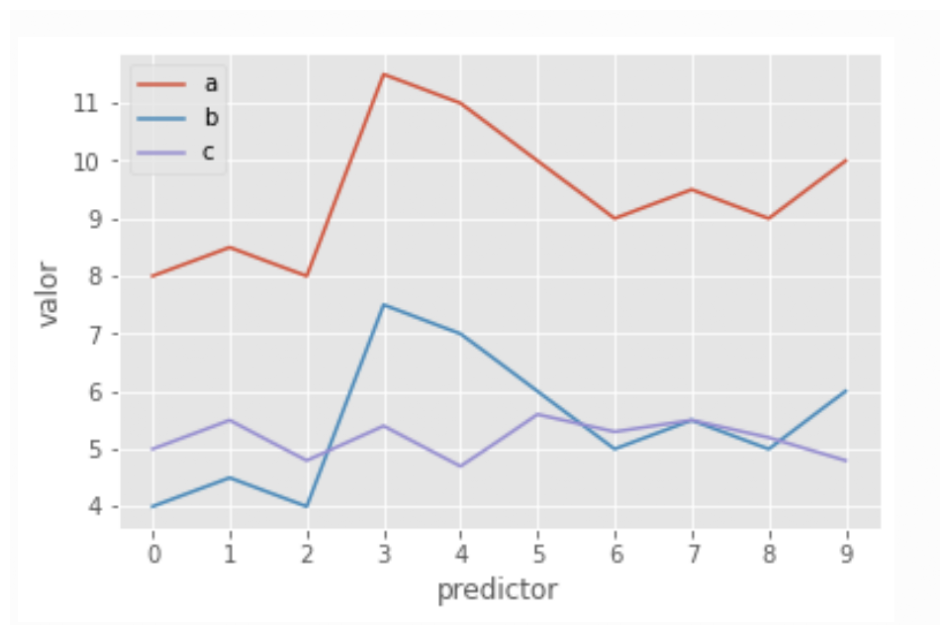

In [52]:
# reading png image file 
# importing pyplot and image from matplotlib 
import matplotlib.pyplot as plt 
import matplotlib.image as img 
im = img.imread('Captura de pantalla41.png') 
  # show image 
plt.figure(figsize=(12, 12))  # Cambia los valores para ajustar el tamaño deseado
plt.axis('off')
plt.imshow(im)
plt.show()

Este ejemplo pone de manifiesto que no existe una única medida de distancia que sea mejor que las demás, sino que depende del contexto en el que se utilice.

#### Correlación Jackknife


El coeficiente de correlación de Pearson resulta efectivo como medida de similitud en ámbitos muy diversos. Sin embargo, tiene la desventaja de no ser robusto frente a outliers, a pesar de que se cumpla la condición de normalidad. Si dos variables tienen un pico o un valle común en una única observación, por ejemplo, por un error de lectura, la correlación va a estar dominada por este registro a pesar de que entre las dos variables no exista correlación real. Lo mismo puede ocurrir en la dirección opuesta. Si dos variables están altamente correlacionadas excepto para una observación, en la que los valores son muy dispares, entonces la correlación existente quedará enmascarada. Una forma de evitarlo es recurrir a la Jackknife correlation, que consiste en calcular todos los posibles coeficientes de correlación entre dos variables si se excluye cada vez una de las observaciones. El promedio de todas las Jackknife correlations atenúa en cierta medida el efecto del outlier.


En resumen: 

El Jackknife es un método de remuestreo que estima la varianza y el sesgo de un estimador eliminando una observación cada vez.
Para la correlación r la idea es:

- Calcular $r_{(i)}$ , la correlación dejando fuera la observación 

- Promediar esas correlaciones.

- Estimar el valor corregido o su sesgo.

La fórmula del estimador jackknife para la correlación es:

$
{\mathrm{r_jack}} = n \cdot r - (n-1)\bar{r}_{(-i)},
$

$
r_{\mathrm{jack}} = n \cdot r - (n-1)\bar{r}_{(-i)}, \quad 
\bar{r}_{(-i)} = \frac{1}{n} \sum_{i=1}^{n} r_{(i)}
$

Cuando se emplea este método, es conveniente calcular la diferencia entre el valor de correlación obtenido por Jackknife correlation  (𝜃¯)  y el que se obtiene si se emplean todas las observaciones  (𝑟¯) . A esta diferencia se le conoce como Bias. Su magnitud es un indicativo de cuanto está influenciada la estimación de la correlación entre dos variables debido a un valor atípico u outlier.

Resumen corto:
- Euclídea → estándar en datos numéricos homogéneos.
- Manhattan → más robusta a outliers.
- Coseno → texto, embeddings, alta dimensión.

In [22]:
import numpy as np

# Ejemplo de datos simulados
np.random.seed(42)
X = np.random.normal(0, 1, 10)
Y = 0.8 * X + np.random.normal(0, 0.3, 10)

# Paso 1: Calcular correlación original
r_original = np.corrcoef(X, Y)[0, 1]

# Paso 2: Calcular correlaciones dejando cada observación fuera
r_jack_list = []
for i in range(len(X)):
    X_jack = np.delete(X, i)
    Y_jack = np.delete(Y, i)
    r_jack = np.corrcoef(X_jack, Y_jack)[0, 1]
    r_jack_list.append(r_jack)

# Paso 3: Promedio de las correlaciones jackknife
r_jack_mean = np.mean(r_jack_list)

# Paso 4: Estimador jackknife
n = len(X)
r_jackknife = n * r_original - (n - 1) * r_jack_mean

print(f"Correlación original: {r_original:.4f}")
print(f"Promedio r_(i): {r_jack_mean:.4f}")
print(f"Correlación Jackknife: {r_jackknife:.4f}")

Correlación original: 0.9262
Promedio r_(i): 0.9266
Correlación Jackknife: 0.9233


Descripción del resultado:

- Calcula la correlación normal entre X y Y.
- Calcula todas las correlaciones dejando una observación fuera (r_(i)).
- Calcula el promedio de esas correlaciones.
- Usa la fórmula jackknife para obtener la estimación ajustada.

##### Ecuacion sesgo 

Sea  $\theta$   el estimador usando todos los datos y  $\theta_{(-i)}$ el estimador eliminando la observación i. Definimos el promedio de los estimadores jackknife como:

$
\bar{\theta}_{(-i)} = \frac{1}{n} \sum_{i=1}^{n} \theta_{(i)}, \quad
$

$
\text{Sesgo}_{\mathrm{jack}} = (n-1)\left(\bar{\theta}_{(-i)} - \theta\right)
$

A pesar de que el método de Jackknife permite aumentar la robustez de la correlación de Pearson, si los outliers son muy extremos su influencia seguirá siendo notable.

#### Escalado de las variables


La escala en la que se miden las variables y la magnitud de su varianza pueden afectar a los resultados obtenidos por clustering. Si una variable tiene una escala mucho mayor que el resto, determinará en gran medida el valor de distancia/similitud obtenido al comparar las observaciones, dirigiendo así la agrupación final. Escalar y centrar las variables antes de calcular la matriz de distancias para que tengan media 0 y desviación estándar 1, asegura que todas las variables tengan el mismo peso cuando se realice el clustering.

La forma más utilizada para escalar y centrar las variables es:

$
z_i = \frac{x_i - \bar{x}}{s_x}
$


#### Ejemplo cálculo distancias


El set de datos USArrests contiene el porcentaje de asaltos (Assault), asesinatos (Murder) y secuestros (Rape) por cada 100,000 habitantes para cada uno de los 50 estados de USA (1973). Además, también incluye el porcentaje de la población de cada estado que vive en zonas rurales (UrbanPoP). Empleando estas variables, se pretende calcular una matriz de distancias que permita identificar los estados más similares.

Dos de las librerías de python que implementan las distancias descritas en este documento (junto con otras) son sklearn.metrics.pairwise_distances y scipy.spatial.distance. En concreto, sklearn permite calcular las distancias: ‘cityblock’, ‘cosine’, ‘euclidean’, ‘l1’, ‘l2’, ‘manhattan’, ‘braycurtis’, ‘canberra’, ‘chebyshev’, ‘correlation’, ‘dice’, ‘hamming’, ‘jaccard’, ‘kulsinski’, ‘mahalanobis’, ‘minkowski’, ‘rogerstanimoto’, ‘russellrao’, ‘seuclidean’, ‘sokalmichener’, ‘sokalsneath’, ‘sqeuclidean’ y ‘yule’.


#### Librerias



In [5]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.font_manager
from matplotlib import style
style.use('ggplot') or plt.style.use('ggplot')

# Preprocesado y modelado
# ==============================================================================
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import scale

# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

In [6]:
USArrests = sm.datasets.get_rdataset("USArrests", "datasets")
datos = USArrests.data
datos.head()


,Murder,Assault,UrbanPop,Rape
rownames,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


##### Cálculo distancias

In [8]:
# Escalado de las variables
# ==============================================================================
datos_scaled = scale(X=datos, axis=0, with_mean=True, with_std=True) 
datos_scaled = pd.DataFrame(datos_scaled, columns=datos.columns, index=datos.index)
datos_scaled.head(4)

,Murder,Assault,UrbanPop,Rape
rownames,,,,
Alabama,1.255179,0.790787,-0.526195,-0.003451
Alaska,0.513019,1.118060,-1.224067,2.509424
Arizona,0.072361,1.493817,1.009122,1.053466
Arkansas,0.234708,0.233212,-1.084492,-0.186794


In [9]:
# Cálculo de distancias
# ==============================================================================
print('------------------')
print('Distancia euclídea')
print('------------------')
distancias = pairwise_distances(
                X      = datos_scaled,
                metric ='euclidean'
             )

# Se descarta la diagonal superior de la matriz
distancias[np.triu_indices(n=distancias.shape[0])] = np.nan

distancias = pd.DataFrame(
                distancias,
                columns=datos_scaled.index,
                index = datos_scaled.index
            )

distancias.iloc[:4,:4]

------------------
Distancia euclídea
------------------


rownames,Alabama,Alaska,Arizona,Arkansas
rownames,,,,
Alabama,NaN,NaN,NaN,NaN
Alaska,2.731204,NaN,NaN,NaN
Arizona,2.316805,2.728061,NaN,NaN
Arkansas,1.302905,2.854730,2.74535,NaN


Se reestructura la matriz de distancias para poder ordenar los pares de observaciones por orden de distancia.

In [13]:
# Top n observaciones más similares
# ==============================================================================
distancias.melt(ignore_index=False, var_name="estado_b", value_name='distancia') \
    .rename_axis("estado_a") \
    .reset_index() \
    .dropna() \
    .sort_values('distancia') \
    .head(10)

,estado_a,estado_b,distancia
728,New Hampshire,Iowa,0.207944
631,New York,Illinois,0.353774
665,Kansas,Indiana,0.433124
1148,Wisconsin,Minnesota,0.499099
928,New Hampshire,Maine,0.504669
785,Oklahoma,Kansas,0.525151
776,Nebraska,Kansas,0.533269
685,Oklahoma,Indiana,0.535710
980,New Mexico,Maryland,0.540825
787,Pennsylvania,Kansas,0.551224


#### Número óptimo de clusters

Determinar el número óptimo de clusters es uno de los pasos más complicados a la hora de aplicar métodos de clustering, sobre todo cuando se trata de partitioning clustering, donde el número se tiene que especificar antes de poder ver los resultados. No existe una forma única de averiguar el número adecuado de clusters. Es un proceso bastante subjetivo que depende en gran medida del algoritmo empleado y de si se dispone de información previa sobre los datos con los que se está trabajando. A pesar de ello, se han desarrollado varias estrategias que ayudan en el proceso.



##### Método Elbow


El método Elbow, también conocido como método del codo, sigue una estrategia comúnmente empleada para encontrar el valor óptimo de un hiperparámetro. La idea es probar un rango de valores del hiperparámetro en cuestión, representar gráficamente los resultados obtenidos con cada uno, e identificar aquel punto de la curva (codo) a partir del cual la mejora deja de ser notable. En los casos de partitioning clustering, como por ejemplo K-means, las observaciones se agrupan de una forma tal que se minimiza la varianza total intra-cluster. El método Elbow calcula la varianza total intra-cluster en función del número de clusters y escoge como óptimo aquel valor a partir del cual añadir más clusters apenas consigue mejoría.

##### Método average silhouette


Se considera como número óptimo de clusters aquel que maximiza la media del silhouette coeficient de todas las observaciones.

#### Metodo de Cluster  K-means

El algoritmo K-means (MacQueen, 1967) agrupa las observaciones en un número predefinido de K clusters de forma que, la suma de las varianzas internas de los clusters, sea lo menor posible. La implementación estándar de K-means (la de scikit-learn, MATLAB, R, etc.) usa exclusivamente la distancia euclídea.

Esto no es casualidad: el algoritmo se basa en minimizar la varianza intra-cluster, es decir, la suma de distancias cuadradas a la media del cluster. Y la media (centroide) solo tiene sentido en el espacio euclídeo porque minimiza esa suma de cuadrados.

Como funciona el algoritmo: Se especifica el número K de clusters que se quieren crear y luego: 

1. Seleccionar de forma aleatoria k observaciones del set de datos como centroides iniciales.

2. Asignar cada una de las observaciones al centroide más cercano.

3. Para cada uno de los K clusters generados en el paso 3, recalcular su centroide.

4. Repetir los pasos 3 y 4 hasta que las asignaciones no cambien o se alcance el número máximo de iteraciones establecido.



Este algoritmo garantiza que, en cada paso, se reduzca la intra-varianza total de los clusters hasta alcanzar un óptimo local. Debido a que el algoritmo de K-means no evalúa todas las posibles distribuciones de las observaciones sino solo parte de ellas, los resultados obtenidos dependen de la asignación aleatoria inicial (paso 2). Por esta razón, es importante ejecutar el algoritmo varias veces (25-50), cada una con una asignación aleatoria inicial distinta, y seleccionar aquella que haya conseguido una menor varianza total.


Ventajas y desventajas


- K-means es uno de los métodos de clustering más utilizados. Destaca por la sencillez y velocidad de su algoritmo, sin embargo, presenta una serie de limitaciones que se deben tener en cuenta.

Sin embargo: 

- Requiere que se indique de antemano el número de clusters que se van a crear. Esto puede ser complicado si no se dispone de información adicional sobre los datos con los que se trabaja. Se han desarrollado varias estrategias para ayudar a identificar potenciales valores óptimos de K (elbow, shilouette), pero todas ellas son orientativas.


- Presenta problemas de robustez frente a outliers. La única solución es excluirlos o recurrir a otros métodos de clustering más robustos como K-medoids (PAM).

#### Ejemplo. Simulacion


Los siguientes datos simulados contienen observaciones que pertenecen a cuatro grupos distintos. Se pretende aplicar K-means-clustering con el objetivo de identificar las agrupaciones reales.

Librerías

Las librerías utilizadas en este ejemplo son:

In [191]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
from matplotlib import style
style.use('ggplot') or plt.style.use('ggplot')

# Preprocesado y modelado
# ==============================================================================
from sklearn.cluster import KMeans
from sklearn.preprocessing import scale
from sklearn.metrics import silhouette_score

# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

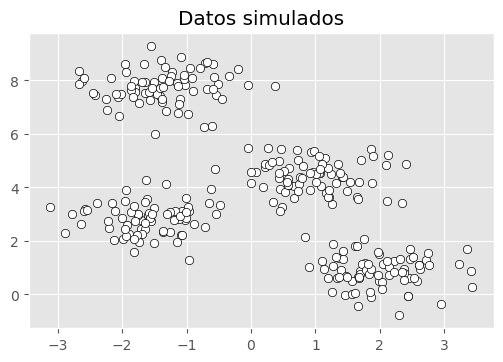

In [193]:
# Simulación de datos
# ==============================================================================
X, y = make_blobs(
        n_samples    = 300, 
        n_features   = 2, 
        centers      = 4, 
        cluster_std  = 0.60, 
        shuffle      = True, 
        random_state = 0
       )

fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.scatter(
    x = X[:, 0],
    y = X[:, 1], 
    c = 'white',
    marker    = 'o',
    edgecolor = 'black', 
)
ax.set_title('Datos simulados');

#### Modelo Kmeans

-Con la clase sklearn.cluster.KMeans de Scikit-Learn se pueden entrenar modelos de clustering utilizando el algoritmo k-means. Entre sus parámetros destacan:

-n_clusters: determina el número  𝐾  de clusters que se van a generar.

-init: estrategia para asignar los centroides iniciales. Por defecto se emplea 'k-means++', una estrategia que trata de alejar los centroides lo máximo posible facilitando la convergencia. Sin embargo, esta estrategia puede ralentizar el proceso cuando hay muchos datos, si esto ocurre, es mejor utilizar 'random'.

-n_init: determina el número de veces que se va a repetir el proceso, cada vez con una asignación aleatoria inicial distinta. Es recomendable que este último valor sea alto, entre 10-25, para no obtener resultados subóptimos debido a una iniciación poco afortunada del proceso.



In [199]:
# Modelo
# ==============================================================================
X_scaled = scale(X)
modelo_kmeans = KMeans(n_clusters=4, n_init=25, random_state=123)
modelo_kmeans.fit(X=X_scaled)

,n_clusters,4
,init,'k-means++'
,n_init,25
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,123
,copy_x,True
,algorithm,'lloyd'


El objeto devuelto por KMeans() contiene entre otros datos: la media de cada una de las variables para cada cluster (cluster_centers_), es decir, los centroides. Un vector indicando a qué cluster se ha asignado cada observación (.labels_) y la suma total de cuadrados internos de todos los clusters (.inertia_).

##### Número de clusters

Al tratarse de una simulación, se conoce el verdadero número de grupos (4) y a cuál de ellos pertenece cada observación. Esto no sucede en la mayoría de casos prácticos, pero es útil como ejemplo ilustrativo cómo funciona K-means.

In [201]:
# Clasificación con el modelo kmeans
# ==============================================================================
y_predict = modelo_kmeans.predict(X=X_scaled)

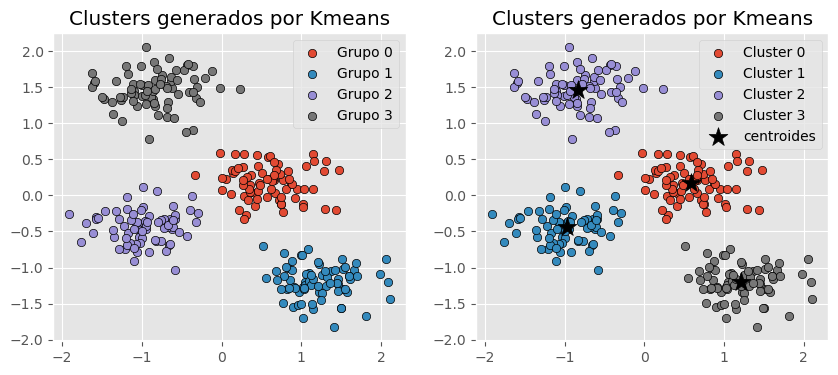

In [203]:
# Representación gráfica: grupos originales vs clusters creados
# ==============================================================================
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Grupos originales
for i in np.unique(y):
    ax[0].scatter(
        x = X_scaled[y == i, 0],
        y = X_scaled[y == i, 1], 
        c = plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
        marker    = 'o',
        edgecolor = 'black', 
        label= f"Grupo {i}"
    )
    
ax[0].set_title('Clusters generados por Kmeans')
ax[0].legend();

for i in np.unique(y_predict):
    ax[1].scatter(
        x = X_scaled[y_predict == i, 0],
        y = X_scaled[y_predict == i, 1], 
        c = plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
        marker    = 'o',
        edgecolor = 'black', 
        label= f"Cluster {i}"
    )
    
ax[1].scatter(
    x = modelo_kmeans.cluster_centers_[:, 0],
    y = modelo_kmeans.cluster_centers_[:, 1], 
    c = 'black',
    s = 200,
    marker = '*',
    label  = 'centroides'
)
ax[1].set_title('Clusters generados por Kmeans')
ax[1].legend();

Este tipo de visualización es muy útil e informativa, sin embargo, solo es posible cuando se trabaja con dos dimensiones. Si los datos contienen más de dos variables (dimensiones), una posible solución es utilizar las dos primeras componentes principales obtenidas con un PCA previo.

Supóngase ahora que se trata de un caso real, en el que se desconoce el número de grupos en los que se subdividen las observaciones. El analista tendría que probar con diferentes valores de  𝐾  y decidir cuál parece más razonable. A continuación, se muestran los resultados para  𝐾=2  y  𝐾=6 .

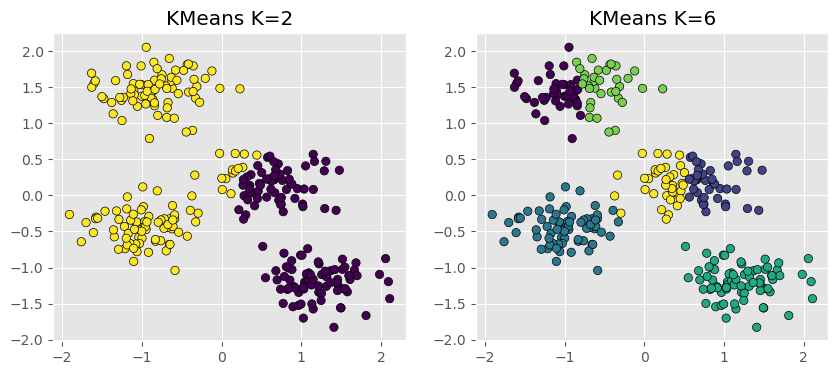

In [187]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Resultados para K = 2
# ==============================================================================
y_predict = KMeans(n_clusters=2, n_init=25, random_state=123).fit_predict(X=X_scaled)
ax[0].scatter(
        x = X_scaled[:, 0],
        y = X_scaled[:, 1], 
        c = y_predict,
        #cmap='viridis',
        marker    = 'o',
        edgecolor = 'black'
    )
ax[0].set_title('KMeans K=2');

# Resultados para K = 6
# ==============================================================================
y_predict = KMeans(n_clusters=6, n_init=25, random_state=123).fit_predict(X=X_scaled)
ax[1].scatter(
        x = X_scaled[:, 0],
        y = X_scaled[:, 1], 
        c = y_predict,
        #cmap='viridis',
        marker    = 'o',
        edgecolor = 'black'
    )
ax[1].set_title('KMeans K=6');

Al observar los resultados obtenidos para K = 2, es intuitivo pensar que el grupo que se encuentra entorno a las coordenadas 𝑥=0.5,𝑦=0  (mayoritariamente considerado como amarillo) debería ser un grupo separado. Para K = 6 no parece muy razonable la separación de los grupos amarillo y azul. Este ejemplo muestra la principal limitación del método de K-means, el hecho de tener que escoger de antemano el número de clusters que se generan.

La deducción anterior solo puede hacerse visualmente cuando se trata de dos dimensiones. Una forma sencilla de estimar el número K óptimo de clusters cuando no se dispone de esta información, es aplicar el algoritmo de K-means para un rango de valores de K e identificar aquel valor a partir del cual la reducción en la suma total de varianza intra-cluster (inertia) deja de ser sustancial. A esta estrategia se la conoce como método del codo o elbow method.

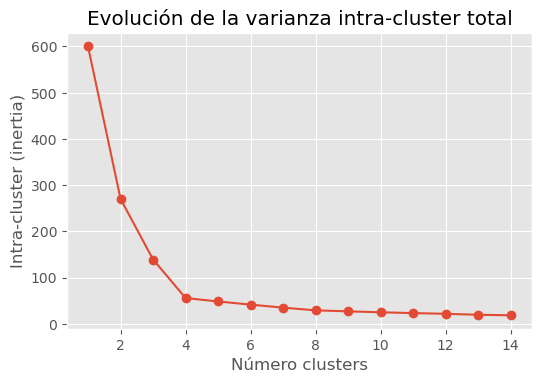

In [190]:
# Método elbow para identificar el número óptimo de clusters
# ==============================================================================
range_n_clusters = range(1, 15)
inertias = []

for n_clusters in range_n_clusters:
    modelo_kmeans = KMeans(
                        n_clusters   = n_clusters, 
                        n_init       = 20, 
                        random_state = 123
                    )
    modelo_kmeans.fit(X_scaled)
    inertias.append(modelo_kmeans.inertia_)

fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.plot(range_n_clusters, inertias, marker='o')
ax.set_title("Evolución de la varianza intra-cluster total")
ax.set_xlabel('Número clusters')
ax.set_ylabel('Intra-cluster (inertia)');


A partir de 4 clusters la reducción en la suma total de cuadrados internos parece estabilizarse, indicando que K = 4 es una buena opción.

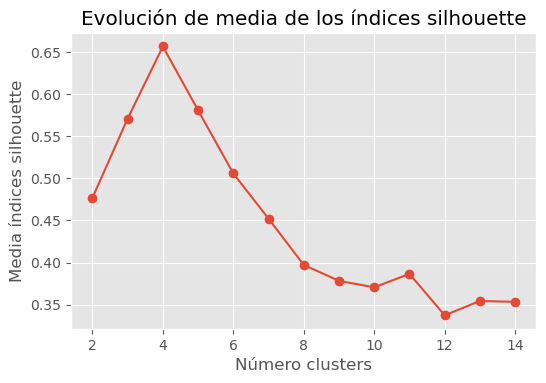

In [193]:
# Método silhouette para identificar el número óptimo de clusters
# ==============================================================================
range_n_clusters = range(2, 15)
valores_medios_silhouette = []

for n_clusters in range_n_clusters:
    modelo_kmeans = KMeans(
                        n_clusters   = n_clusters, 
                        n_init       = 20, 
                        random_state = 123
                    )
    cluster_labels = modelo_kmeans.fit_predict(X_scaled)
    silhouette_avg = silhouette_score(X_scaled, cluster_labels)
    valores_medios_silhouette.append(silhouette_avg)
    
fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.plot(range_n_clusters, valores_medios_silhouette, marker='o')
ax.set_title("Evolución de media de los índices silhouette")
ax.set_xlabel('Número clusters')
ax.set_ylabel('Media índices silhouette');

El valor medio de los índices silhouette se maximiza con 4 clusters. Acorde a este criterio, K = 4 es la mejor opción.

Ambos criterios, elbow y silhouette, identifican el valor K= como valor óptimo de clusters.

#### K-medoids

K-medoids es un método de clustering muy similar a K-means en cuanto a que ambos agrupan las observaciones en K clusters, donde K es un valor preestablecido por el analista. La diferencia es que, en K-medoids, cada cluster está representado por una observación presente en el cluster (medoid), mientras que en K-means cada cluster está representado por su centroide, que se corresponde con el promedio de todas las observaciones del cluster pero con ninguna en particular.

Una definición más exacta del término medoid es: elemento dentro de un cluster cuya distancia (diferencia) promedio entre él y todos los demás elementos del mismo cluster es lo menor posible. Se corresponde con el elemento más central del cluster y por lo tanto puede considerarse como el más representativo. El hecho de utilizar medoids en lugar de centroides hace de K-medoids un método más robusto que K-means, viéndose menos afectado por outliers o ruido. A modo de idea intuitiva puede considerarse como la analogía entre media y mediana.

El algoritmo más empleado para aplicar K-medoids se conoce como PAM (Partitioning Around Medoids) y sigue los siguientes pasos:

1. Seleccionar K observaciones aleatorias como medoids iniciales. También es posible identificarlas de forma específica.

2. Calcular la matriz de distancia entre todas las observaciones si esta no se ha calculado anteriormente.

3. Asignar cada observación a su medoid más cercano.

4. Para cada uno de los clusters creados, comprobar si seleccionando otra observación como medoid se consigue reducir la distancia promedio del cluster, si esto ocurre, seleccionar la observación que consigue una mayor reducción como nuevo medoid.

5. Si al menos un medoid ha cambiado en el paso 4, volver al paso 3, de lo contrario, se termina el proceso.


Ejemplos de distancias que puedes usar con K-medoids
- Euclídea (por defecto, como K-means)
- Manhattan (L1)
- Coseno
- Mahalanobis


In [ ]:
## Esto se escribe en google colab pues algunas librerías no estan instaladas: 
# 0 !pip install scikit-learn-extra
# 1. Bajar la versión de NumPy a una compatible
#!pip install "numpy<2" --quiet

# 2. Instalar scikit-learn-extra
#!pip install scikit-learn-extra --quiet

# 3. Reinicia el runtime de Colab para que tome los cambios
#import os
#os.kill(os.getpid(), 9)

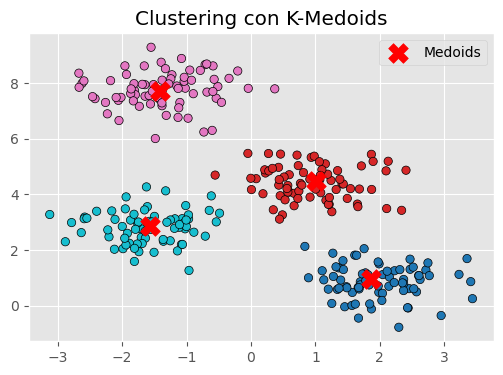

In [185]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn_extra.cluster import KMedoids

# Simulación de datos
# ==============================================================================
X, y = make_blobs(
    n_samples    = 300, 
    n_features   = 2, 
    centers      = 4, 
    cluster_std  = 0.60, 
    shuffle      = True, 
    random_state = 0
)

# Ajuste del modelo K-Medoids
# ==============================================================================
kmedoids = KMedoids(
    n_clusters=4, 
    metric='euclidean', 
    init='k-medoids++', 
    random_state=0
)
kmedoids.fit(X)

# Predicciones
labels = kmedoids.labels_
medoids = kmedoids.cluster_centers_

# Visualización de resultados
# ==============================================================================
fig, ax = plt.subplots(figsize=(6, 4))
scatter = ax.scatter(
    x = X[:, 0],
    y = X[:, 1], 
    c = labels,
    cmap = "tab10",
    marker='o',
    edgecolor='black'
)

# Graficar los medoids
ax.scatter(
    medoids[:, 0],
    medoids[:, 1],
    c='red',
    s=200,
    marker='X',
    label='Medoids'
)

ax.set_title('Clustering con K-Medoids')
ax.legend()
plt.show()


A diferencia del algoritmo K-means, en el que se minimiza la suma total de cuadrados intra-cluster (suma de las distancias al cuadrado de cada observación respecto a su centroide), el algoritmo K-medoids minimiza la suma de las diferencias de cada observación respecto a su medoid.

Por lo general, el método de K-medoids se utiliza cuando se conoce o se sospecha de la presencia de outliers. Si esto ocurre, es recomendable utilizar como medida de similitud la distancia de Manhattan, ya que es menos sensible a outliers que la euclídea.

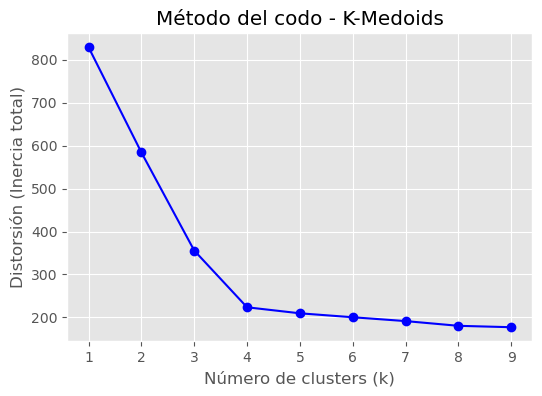

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn_extra.cluster import KMedoids

# Simulación de datos
# ==============================================================================
X, y = make_blobs(
    n_samples    = 300, 
    n_features   = 2, 
    centers      = 4, 
    cluster_std  = 0.60, 
    shuffle      = True, 
    random_state = 0
)

# Cálculo del método del codo para K-Medoids
# ==============================================================================
distorsiones = []
K = range(1, 10)

for k in K:
    modelo = KMedoids(
        n_clusters=k,
        metric='euclidean',
        init='k-medoids++',
        random_state=0
    )
    modelo.fit(X)
    # Distancia total intra-cluster
    distorsiones.append(modelo.inertia_)

# Visualización del criterio del codo
# ==============================================================================
plt.figure(figsize=(6, 4))
plt.plot(K, distorsiones, 'o-', color='blue')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Distorsión (Inercia total)')
plt.title('Método del codo - K-Medoids')
plt.grid(True)
plt.show()

#### Ventajas y desventajas

- K-medoids es un método de clustering más robusto que K-means, por lo es más adecuado cuando el set de datos contiene outliers o ruido.

- Al igual que K-means, necesita que se especifique de antemano el número de clusters que se van a crear. Esto puede ser complicado de determinar si no se dispone de información adicional sobre los datos. Muchas de las estrategias empleadas en K-means para identificar el número óptimo, pueden aplicarse en K-medoids.

- Para sets de datos grandes se necesitan muchos recursos computacionales. 


El algoritmo K-medoids está implementado en la clase KMedoids de la librería sklearn_extra. Su funcionamiento es análogo al descrito en el apartado de K-means. También está disponible en la librería PyClustering.


#### Hierarchical clustering

Hierarchical clustering es una alternativa a los métodos de partitioning clustering que no requiere que se pre-especifique el número de clusters. Los métodos que engloba el hierarchical clustering se subdividen en dos tipos dependiendo de la estrategia seguida para crear los grupos:

Aglomerativo (agglomerative clustering o bottom-up): el agrupamiento se inicia con todas las observaciones separadas, cada una formando un cluster individual. Los clusters se van combinado a medida que la estructura crece hasta converger en uno solo.

Divisivo (divisive clustering o top-down): es la estrategia opuesta al aglomerativo. Se inicia con todas las observaciones contenidas en un mismo cluster y se suceden divisiones hasta que cada observación forma un cluster* individual.

En ambos casos, los resultados pueden representarse de forma muy intuitiva en una estructura de árbol llamada dendrograma.

#### Aglomerativo

El algoritmo seguido para por el clustering aglomerativo es:

1. Considerar cada una de las n observaciones como un cluster individual, formando así la base del dendrograma (hojas).

2. Proceso iterativo hasta que todas las observaciones pertenecen a un único cluster:

- 2.1 Calcular la distancia entre cada posible par de los n clusters. El investigador debe determinar el tipo de medida empleada para cuantificar la similitud entre observaciones o grupos (distancia y linkage).

- 2.2 Los dos clusters más similares se fusionan, de forma que quedan n-1 clusters.

3. Cortar la estructura de árbol generada (dendrograma) a una determinada altura para crear los clusters finales.



Para que el proceso de agrupamiento pueda llevarse a cabo tal como indica el algoritmo anterior, es necesario definir cómo se cuantifica la similitud entre dos clusters. Es decir, se tiene que extender el concepto de distancia entre pares de observaciones para que sea aplicable a pares de grupos, cada uno formado por varias observaciones. A este proceso se le conoce como linkage. A continuación, se describen los 5 tipos de linkage más empleados y sus definiciones.

- Complete or Maximum: se calcula la distancia entre todos los posibles pares formados por una observación del cluster A y una del cluster B. La mayor de todas ellas se selecciona como la distancia entre los dos clusters. Se trata de la medida más conservadora (maximal intercluster dissimilarity).

- Single or Minimum: se calcula la distancia entre todos los posibles pares formados por una observación del cluster A y una del cluster B. La menor de todas ellas se selecciona como la distancia entre los dos clusters. Se trata de la medida menos conservadora (minimal intercluster dissimilarity).

- Average: Se calcula la distancia entre todos los posibles pares formados por una observación del cluster A y una del cluster B. El valor promedio de todas ellas se selecciona como la distancia entre los dos clusters (mean intercluster dissimilarity).

- Centroid: Se calcula el centroide de cada uno de los clusters y se selecciona la distancia entre ellos como la distancia entre los dos clusters.

- Ward: Se trata de un método general. La selección del par de clusters que se combinan en cada paso del agglomerative hierarchical clustering se basa en el valor óptimo de una función objetivo, pudiendo ser esta última cualquier función definida por el analista. El método Ward's minimum variance es un caso particular en el que el objetivo es minimizar la suma total de varianza intra-cluster. En cada paso, se identifican aquellos 2 clusters cuya fusión conlleva menor incremento de la varianza total intra-cluster. Esta es la misma métrica que se minimiza en K-means.

Los métodos de complete, average y Ward's minimum variance suelen ser los preferidos por los analistas debido a que generan dendrogramas más claros. Sin embargo, no se puede determinar que uno sea mejor que otro, ya que depende del caso de estudio en cuestión. Por ejemplo, en genómica, se emplea con frecuencia el método de centroides. Junto con los resultados de un proceso de hierarchical clustering siempre hay que indicar qué distancia se ha empleado, así como el tipo de linkage, ya que, dependiendo de estos, los resultados pueden variar en gran medida.

Si se utiliza linkage=“ward”, solo se permite “euclidean”.

A diferencia del clustering aglomerativo, en el que hay que elegir un tipo de distancia y un método de linkage

#### Dendrograma

Los resultados del hierarchical clustering pueden representarse como un árbol en el que las ramas representan la jerarquía con la que se van sucediendo las uniones de clusters.

Supóngase que se dispone de 45 observaciones en un espacio de dos dimensiones, a los que se les aplica hierarchical clustering para intentar identificar grupos. El siguiente dendrograma representa los resultados obtenidos.

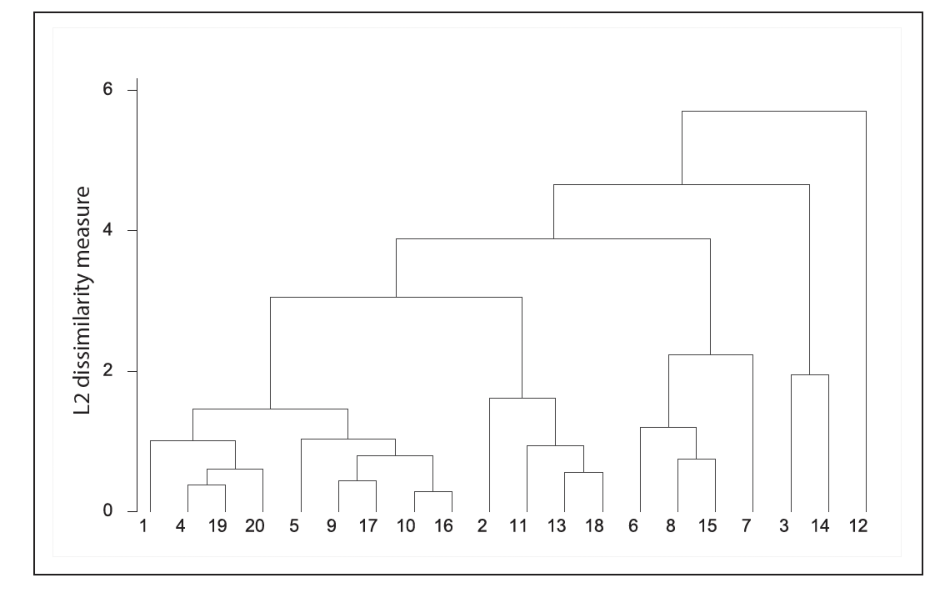

In [227]:
# reading png image file 
# importing pyplot and image from matplotlib 
import matplotlib.pyplot as plt 
import matplotlib.image as img 
im = img.imread('Captura43.png') 
  # show image 
plt.figure(figsize=(12, 12))  # Cambia los valores para ajustar el tamaño deseado
plt.axis('off')
plt.imshow(im)
plt.show()

Por ejemplo, la observación 4  es la más similar a la 19  ya que es la primera fusión que recibe la observación 19 (y viceversa). Podría resultar tentador decir que la observación 5, situada inmediatamente a la derecha de la 19, es la siguiente más similar, sin embargo, las observaciones 1 y 20  son más similares a la 19 a pesar de que se encuentran más alejadas en el eje horizontal. 




Además de representar en un dendrograma la similitud entre observaciones, se tiene que identificar el número de clusters creados y qué observaciones forman parte de cada uno. Si se realiza un corte horizontal a una determinada altura del dendrograma, el número de ramas que sobrepasan (en sentido ascendente) dicho corte se corresponde con el número de clusters. La siguiente imagen muestra dos veces el mismo dendrograma. La altura de corte tiene por lo tanto la misma función que el valor K en K-means-clustering: controla el número de clusters obtenidos.

Con un solo dendrograma se dispone de la flexibilidad para generar cualquier número de clusters desde 1 a n. La selección del número óptimo puede valorarse de forma visual, tratando de identificar las ramas principales en base a la altura a la que ocurren las uniones. En el ejemplo expuesto es razonable elegir 6  clusters.

In [68]:
def plot_dendrogram(model, **kwargs):
    '''
    Esta función extrae la información de un modelo AgglomerativeClustering
    y representa su dendograma con la función dendogram de scipy.cluster.hierarchy
    '''
    
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack([model.children_, model.distances_,
                                      counts]).astype(float)

    # Plot
    dendrogram(linkage_matrix, **kwargs)

In [70]:
# Modelos
from sklearn.cluster import AgglomerativeClustering
# ==============================================================================
modelo_hclust_complete = AgglomerativeClustering(
                            metric = 'euclidean',
                            linkage  = 'complete',
                            distance_threshold = 0,
                            n_clusters         = None
                        )
modelo_hclust_complete.fit(X=X_scaled)

modelo_hclust_average = AgglomerativeClustering(
                            metric = 'euclidean',
                            linkage  = 'average',
                            distance_threshold = 0,
                            n_clusters         = None
                        )
modelo_hclust_average.fit(X=X_scaled)

modelo_hclust_ward = AgglomerativeClustering(
                            metric = 'euclidean',
                            linkage  = 'ward',
                            distance_threshold = 0,
                            n_clusters         = None
                     )
modelo_hclust_ward.fit(X=X_scaled)

,n_clusters,None
,metric,'euclidean'
,memory,None
,connectivity,None
,compute_full_tree,'auto'
,linkage,'ward'
,distance_threshold,0
,compute_distances,False


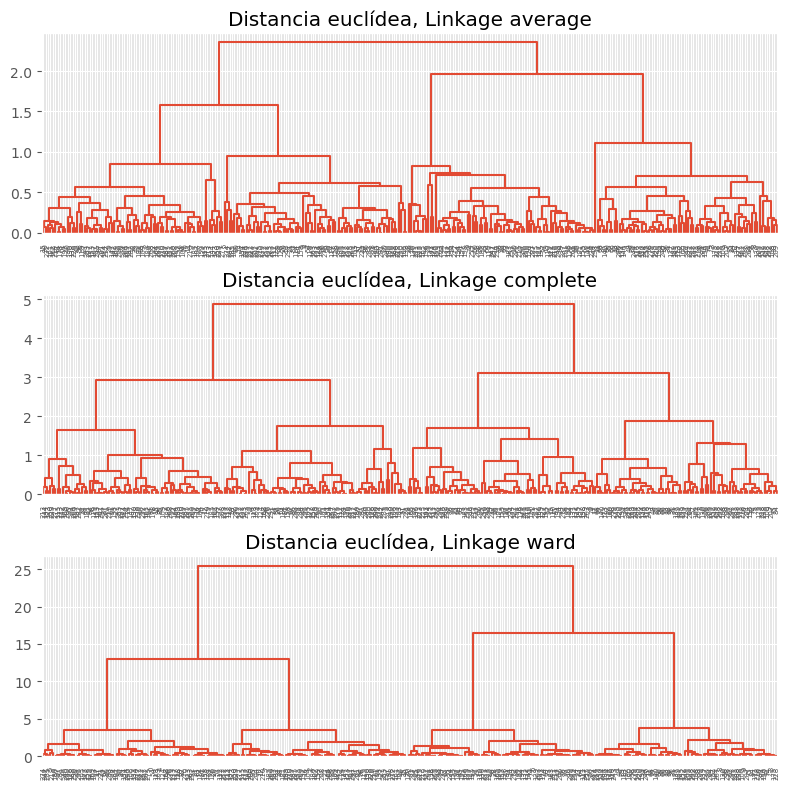

In [266]:
# Dendrogramas
# ==============================================================================
fig, axs = plt.subplots(3, 1, figsize=(8, 8))
plot_dendrogram(modelo_hclust_average, color_threshold=0, ax=axs[0])
axs[0].set_title("Distancia euclídea, Linkage average")
plot_dendrogram(modelo_hclust_complete, color_threshold=0, ax=axs[1])
axs[1].set_title("Distancia euclídea, Linkage complete")
plot_dendrogram(modelo_hclust_ward, color_threshold=0, ax=axs[2])
axs[2].set_title("Distancia euclídea, Linkage ward")
plt.tight_layout();

En este caso, los tres tipos de linkage identifican claramente 4 clusters, si bien esto no significa que en los 3 dendrogramas los clusters estén formados por exactamente las mismas observaciones.

Otra forma de identificar potenciales valores óptimos para el número de clusters en modelos hierarchical clustering es mediante los índices silhouette

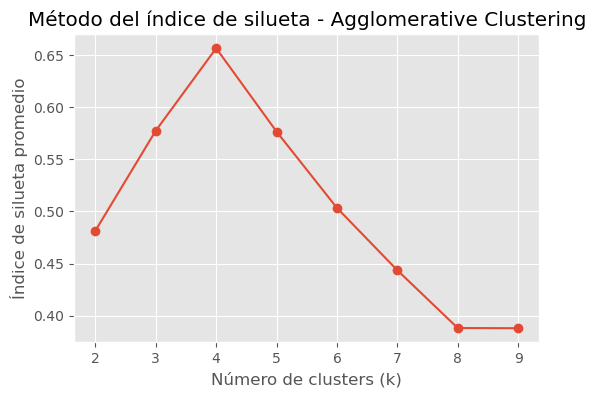

Número óptimo de clusters según silueta: 4


In [72]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Rango de número de clusters a evaluar
rango_clusters = range(2, 10)
resultados = []

for k in rango_clusters:
    modelo = AgglomerativeClustering(
        metric='euclidean',
        linkage='ward',  # Cambiar a 'complete' o 'average' si quieres comparar
        n_clusters=k
    )
    etiquetas = modelo.fit_predict(X_scaled)
    silueta = silhouette_score(X_scaled, etiquetas)
    resultados.append(silueta)

# Visualización de los resultados
plt.figure(figsize=(6, 4))
plt.plot(rango_clusters, resultados, marker='o')
plt.xlabel("Número de clusters (k)")
plt.ylabel("Índice de silueta promedio")
plt.title("Método del índice de silueta - Agglomerative Clustering")
plt.grid(True)
plt.show()

# Mejor número de clusters
k_optimo = rango_clusters[np.argmax(resultados)]
print(f"Número óptimo de clusters según silueta: {k_optimo}")

#### Density based clustering (DBSCAN)

Density-based spatial clustering of applications with noise (DBSCAN) fue presentado en 1996 por Ester et al. como una forma de identificar clusters siguiendo el modo intuitivo en el que lo hace el cerebro humano, identificando regiones con alta densidad de observaciones separadas por regiones de baja densidad.

El algoritmo DBSCAN necesita dos parámetros:

- Epsilon  (𝜖) : radio que define la región vecina a una observación, también llamada  𝜖 -neighborhood.

- Minimum points (min_samples): número mínimo de observaciones dentro de la región epsilon.

Empleando estos dos parámetros, cada observación del set de datos se puede clasificar en una de las siguientes tres categorías:

- Core point: Un core point es un punto que está en una zona suficientemente densa.
Se dice que es core si, cuando dibujas un círculo de radio 𝜖 alrededor de él, hay al menos min_samples puntos dentro de ese círculo (incluyéndolo a él mismo).


Si dentro del círculo hay al menos min_samples personas (contándote a ti mismo), entonces eres un core point — estás en una parte de la fiesta que está “llena de gente”.
Si no hay suficientes personas en tu círculo, entonces no eres core (puedes ser un border point si estás cerca de alguien que sí es core, o noise point si estás aislado).

- Border point: observación no satisface el mínimo de observaciones vecinas para ser core point pero que pertenece al  𝜖 -neighborhood de otra observación que sí es core point.

- Noise u outlier: observación que no es core point ni border point.

#### Algoritmo


1. Para cada observación  𝑥𝑖  calcular la distancia entre ella y el resto de observaciones. Si en su  𝜖 -neighborhood hay un número de observaciones  ≥𝑚𝑖𝑛𝑠𝑎𝑚𝑝𝑙𝑒𝑠  marcar la observación como core point, de lo contrario marcarla como visitada.

2. Para cada observación  𝑥𝑖  marcada como core point, si todavía no ha sido asignada a ningún cluster, crear uno nuevo y asignarla a él. Encontrar recursivamente todas las observaciones densamente conectadas a ella y asignarlas al mismo cluster.

3. Iterar el mismo proceso para todas las observaciones que no hayan sido visitadas.

4. Aquellas observaciones que tras haber sido visitadas no pertenecen a ningún cluster se marcan como outliers

Como resultado, todo cluster cumple dos propiedades: todos los puntos que forman parte de un mismo cluster están densamente conectados entre ellos y, si una observación  𝐴  es densamente alcanzable desde cualquier otra observación de un cluster, entonces  𝐴  también pertenece al cluster.


####Hiperparámetros


Como ocurre en muchas otras técnicas estadísticas, en DBSCAN no existe una forma única y exacta de encontrar el valor adecuado de epsilon  (𝜖)  y  𝑚𝑖𝑛𝑠𝑎𝑚𝑝𝑙𝑒𝑠 . A modo orientativo se pueden seguir las siguientes premisas:

- 𝑚𝑖𝑛𝑠𝑎𝑚𝑝𝑙𝑒𝑠 : cuanto mayor sea el tamaño del set de datos, mayor debe ser el valor mínimo de observaciones vecinas. En el libro Practical Guide to Cluster Analysis in R recomiendan no bajar nunca de 3. Si los datos contienen niveles altos de ruido, aumentar  𝑚𝑖𝑛𝑠𝑎𝑚𝑝𝑙𝑒𝑠  favorecerá la creación de clusters significativos menos influenciados por outliers.

- epsilon: el parámetro ε (epsilon) controla el radio de vecindad que usamos para decidir si un punto está "cerca" de otros puntos.

Efecto de cambiar ε:
- ε muy pequeño:
- El círculo es muy chico → casi no hay vecinos.
- DBSCAN detecta pocos clusters o marca muchos puntos como ruido.
- Riesgo: dividir un solo grupo en varias partes pequeñas.

ε muy grande:
- El círculo es muy grande → todos tienen muchos vecinos.
- DBSCAN puede unir varios grupos distintos en un solo cluster gigante.
- Riesgo: perder separación entre grupos verdaderos.


#### Ventajas

-No requiere que el usuario especifique el número de clusters.

-Es independiente de la forma que tengan los clusters.

-Puede identificar outliers, por lo que los clusters generados no se ven influenciados por ellos.


In [77]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
from matplotlib import style
style.use('ggplot') or plt.style.use('ggplot')

# Preprocesado y modelado
# ==============================================================================
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import scale
from sklearn.metrics import silhouette_score

# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

#### Datos

In [80]:
url = 'https://raw.githubusercontent.com/JoaquinAmatRodrigo/' \
      + 'Estadistica-machine-learning-python/master/data/multishape.csv'
datos = pd.read_csv(url)
datos.head()

,x,y,shape
0,-0.803739,-0.853053,1
1,0.852851,0.367618,1
2,0.927180,-0.274902,1
3,-0.752626,-0.511565,1
4,0.706846,0.810679,1


Con la clase sklearn.cluster.DBSCAN de Scikit-Learn se pueden entrenar modelos de clustering utilizando el algoritmo DBSCAN. Entre sus parámetros destacan:

-eps: .

-min_samples: .

-metric: métrica utilizada como distancia. Puede ser: “euclidean”,  “manhattan”,or  “cosine”,

In [83]:
# Escalado de datos
# ==============================================================================
X = datos.drop(columns='shape').to_numpy()
X_scaled = scale(X)

In [85]:
# Modelo
# ==============================================================================
modelo_dbscan = DBSCAN(
                    eps          = 0.2,
                    min_samples  = 5,
                    metric       = 'euclidean',
                )

modelo_dbscan.fit(X=X_scaled)

,eps,0.2
,min_samples,5
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


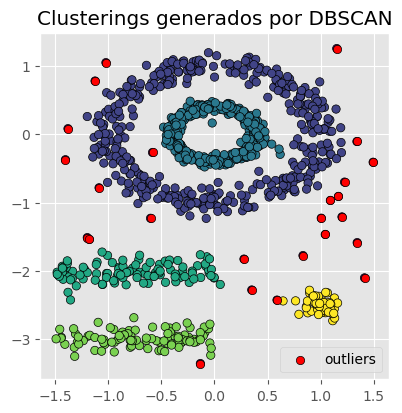

In [87]:
# Clasificación
# ==============================================================================
labels = modelo_dbscan.labels_

fig, ax = plt.subplots(1, 1, figsize=(4.5, 4.5))

ax.scatter(
    x = X[:, 0],
    y = X[:, 1], 
    c = labels,
    marker    = 'o',
    edgecolor = 'black'
)

# Los outliers se identifican con el label -1
ax.scatter(
    x = X[labels == -1, 0],
    y = X[labels == -1, 1], 
    c = 'red',
    marker    = 'o',
    edgecolor = 'black',
    label = 'outliers'
)

ax.legend()
ax.set_title('Clusterings generados por DBSCAN');

In [309]:
# Número de clusters y observaciones "outliers"
# ==============================================================================
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise    = list(labels).count(-1)

print(f'Número de clusters encontrados: {n_clusters}')
print(f'Número de outliers encontrados: {n_noise}')

Número de clusters encontrados: 5
Número de outliers encontrados: 25


##### Limitaciones del clustering


1. El clustering puede ser una herramienta muy útil para encontrar agrupaciones en los datos, sobre todo a medida que el volumen de los mismos aumenta. Sin embargo, es importante recordar sus limitaciones o problemas que pueden surgir al aplicarlo. Algunas de ellas son:

Pequeñas decisiones pueden tener grandes consecuencias:a la hora de utilizar los métodos de clustering se tienen que tomar decisiones que influyen en gran medida en los resultados obtenidos. No existe una única respuesta correcta, por lo que en la práctica se prueban diferentes opciones.

-Escalado y centrado de las variables

-Qué medida de distancia/similitud emplear

-Número de clusters

-Tipo de linkage empleado en hierarchical clustering


2. Validación de los clusters obtenidos: no es fácil comprobar la validez de los resultados ya que en la mayoría de escenarios se desconoce la verdadera agrupación.

3. Falta de robustez: los métodos de K-means-clustering e hierarchical clustering asignan obligatoriamente cada observación a un grupo. Si existe en la muestra algún outlier, a pesar de que realmente no pertenezca a ningún grupo, el algoritmo lo asignará a uno de ellos provocando una distorsión significativa del cluster en cuestión. Algunas alternativas son k-medoids y DBSCAN.


#### Ejemplo 2

En este conjunto de datos, la agrupación jerárquica se utiliza para clasificar los 25 países europeos según su consumo de proteínas.

The dataset is inputed and the missing data is checked to make sure there is no NA value in the dataset

In [90]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# Guardar en tu computador como archivo CSV
food_data.to_csv("protein.csv", index=False)

In [92]:
# 2. Inspeccionar
print(food_data.head())
print(food_data.info())
print(food_data.describe())

          Country   RedMeat   WhiteMeat   Eggs   Milk   Fish   Cereals  \
0         Albania      10.1         1.4    0.5    8.9    0.2      42.3   
1         Austria       8.9        14.0    4.3   19.9    2.1      28.0   
2         Belgium      13.5         9.3    4.1   17.5    4.5      26.6   
3        Bulgaria       7.8         6.0    1.6    8.3    1.2      56.7   
4  Czechoslovakia       9.7        11.4    2.8   12.5    2.0      34.3   

    Starch   Nuts   Fr&Veg  
0      0.6    5.5      1.7  
1      3.6    1.3      4.3  
2      5.7    2.1      4.0  
3      1.1    3.7      4.2  
4      5.0    1.1      4.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Country     25 non-null     object 
 1    RedMeat    25 non-null     float64
 2    WhiteMeat  25 non-null     float64
 3    Eggs       25 non-null     float64
 4    Milk       25 non-null    

In [120]:
print(food_data.shape)

(25, 11)


In [94]:
# 3. Eliminar columnas irrelevantes (ej: 'Country' que es categórica)
X = food_data.drop(columns=['Country'])

In [96]:
# 4. Escalar los datos (muy importante para clustering)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [98]:
# 5. (Opcional) Reducir dimensiones con PCA para visualizar en 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

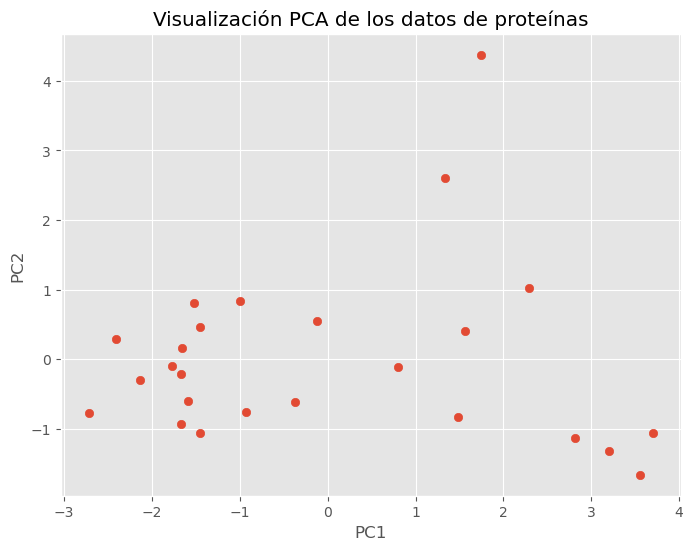

In [100]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1])
plt.title("Visualización PCA de los datos de proteínas")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

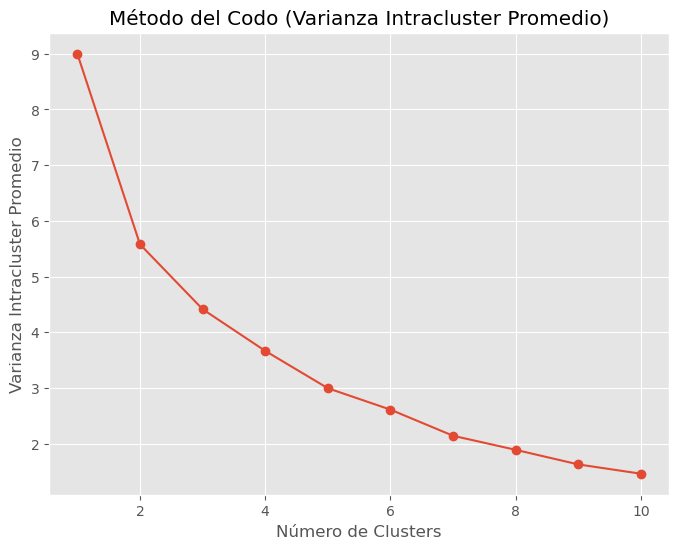

In [104]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Número de puntos
n = X_scaled.shape[0]

# 6. Determinar número óptimo de clusters con el método del codo
varianza_intracluster = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    # Varianza intracluster = inercia / número de observaciones
    varianza_intracluster.append(kmeans.inertia_ / n)

# Gráfico del codo usando varianza intracluster
plt.figure(figsize=(8, 6))
plt.plot(K_range, varianza_intracluster, marker='o')
plt.title("Método del Codo (Varianza Intracluster Promedio)")
plt.xlabel("Número de Clusters")
plt.ylabel("Varianza Intracluster Promedio")
plt.grid(True)
plt.show()


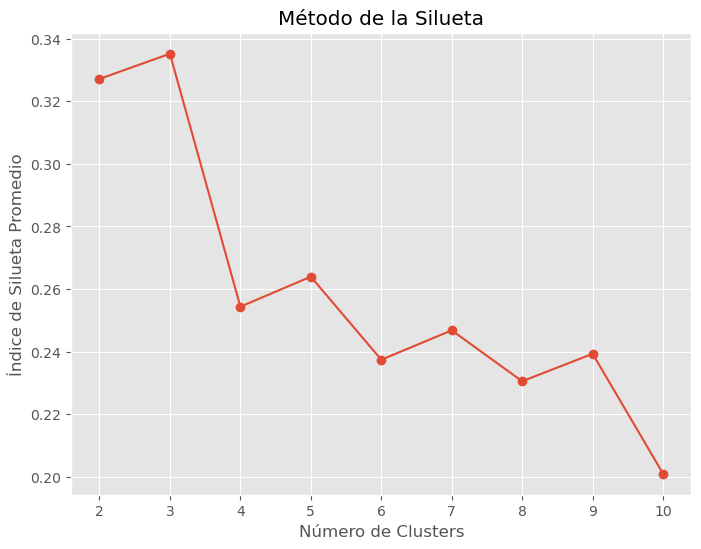

✅ Número óptimo de clusters según Silueta: 3


In [108]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = []
K_range = range(2, 11)  # Silhouette no se define para k=1

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

# Gráfico del criterio de silueta
plt.figure(figsize=(8, 6))
plt.plot(K_range, silhouette_scores, marker='o')
plt.title("Método de la Silueta")
plt.xlabel("Número de Clusters")
plt.ylabel("Índice de Silueta Promedio")
plt.grid(True)
plt.show()

# Mejor número de clusters
k_optimo = K_range[np.argmax(silhouette_scores)]
print(f"✅ Número óptimo de clusters según Silueta: {k_optimo}")

El clustering jerárquico nos permite ver cómo se agrupan los países poco a poco, y lo más común es visualizarlo con un dendrograma.

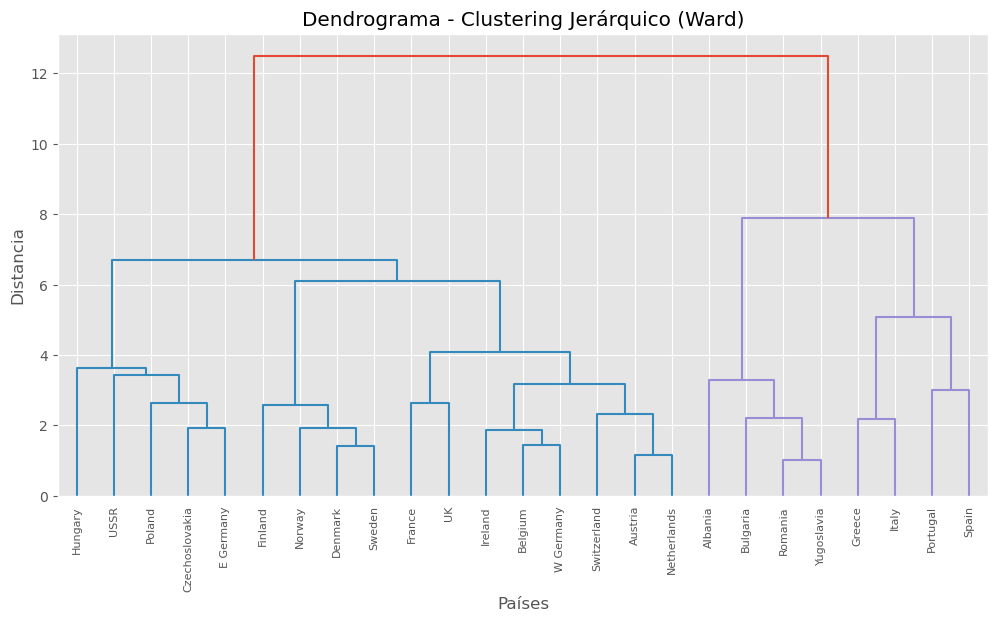

           Country  Cluster_Hier
15          Poland             1
22            USSR             1
4   Czechoslovakia             1
6        E Germany             1
10         Hungary             1
8           France             2
14          Norway             2
13     Netherlands             2
23       W Germany             2
11         Ireland             2
19          Sweden             2
20     Switzerland             2
7          Finland             2
5          Denmark             2
2          Belgium             2
1          Austria             2
21              UK             2
0          Albania             3
24      Yugoslavia             3
17         Romania             3
3         Bulgaria             3
16        Portugal             4
9           Greece             4
18           Spain             4
12           Italy             4


In [136]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import matplotlib.pyplot as plt

# 1. Cargar los datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Seleccionar solo las variables numéricas (quitamos 'Country')
X = food_data.drop(columns=['Country'])

# 3. Escalar los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Clustering jerárquico (método Ward)
Z = linkage(X_scaled, method='ward')

# 5. Graficar dendrograma
plt.figure(figsize=(12,6))
dendrogram(Z, labels=food_data['Country'].values, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrograma - Clustering Jerárquico (Ward)")
plt.xlabel("Países")
plt.ylabel("Distancia")
plt.show()

# 6. Elegir número de clusters (ejemplo: 4)
clusters_hier = fcluster(Z, t=4, criterion='maxclust')

# 7. Agregar los clusters al dataframe
food_data['Cluster_Hier'] = clusters_hier

# 8. Ver resultados
print(food_data[['Country', 'Cluster_Hier']].sort_values(by='Cluster_Hier').head(25))

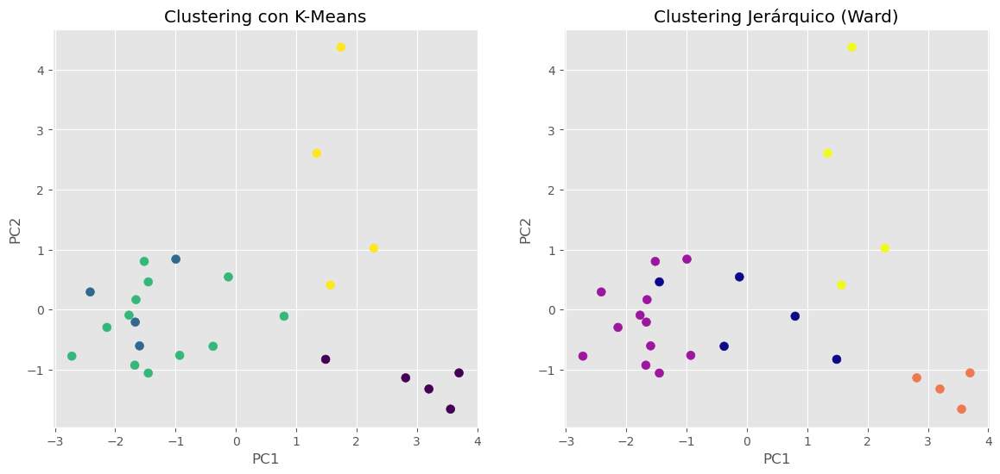

           Country  Cluster_KMeans  Cluster_Hier
0          Albania               0             3
1          Austria               2             2
2          Belgium               2             2
3         Bulgaria               0             3
4   Czechoslovakia               2             1
5          Denmark               1             2
6        E Germany               2             1
7          Finland               1             2
8           France               2             2
9           Greece               3             4
10         Hungary               0             1
11         Ireland               2             2
12           Italy               3             4
13     Netherlands               2             2
14          Norway               1             2


In [139]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster
import matplotlib.pyplot as plt

# 1. Cargar los datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Seleccionar solo las variables numéricas
X = food_data.drop(columns=['Country'])

# 3. Escalar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Reducir con PCA para visualización
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 5. K-Means clustering (4 clusters como ejemplo)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters_kmeans = kmeans.fit_predict(X_scaled)
food_data["Cluster_KMeans"] = clusters_kmeans

# 6. Clustering jerárquico (Ward, 4 clusters)
Z = linkage(X_scaled, method="ward")
clusters_hier = fcluster(Z, t=4, criterion="maxclust")
food_data["Cluster_Hier"] = clusters_hier

# 7. Visualización comparativa
fig, axes = plt.subplots(1, 2, figsize=(14,6))

# --- K-Means ---
axes[0].scatter(X_pca[:,0], X_pca[:,1], c=clusters_kmeans, cmap="viridis", s=50)
axes[0].set_title("Clustering con K-Means")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

# --- Jerárquico ---
axes[1].scatter(X_pca[:,0], X_pca[:,1], c=clusters_hier, cmap="plasma", s=50)
axes[1].set_title("Clustering Jerárquico (Ward)")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.show()

# 8. Mostrar primeros resultados de asignación de clusters
print(food_data[["Country", "Cluster_KMeans", "Cluster_Hier"]].head(15))

Hagamos un análisis de similitud entre los clusters obtenidos por K-Means y Jerárquico. Para eso, lo más claro es construir una tabla de contingencia (cross-tabulation), que muestra cuántos países coinciden en cada combinación de clusters.

In [142]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. K-Means (4 clusters)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
food_data["Cluster_KMeans"] = kmeans.fit_predict(X_scaled)

# 4. Jerárquico (4 clusters)
Z = linkage(X_scaled, method="ward")
food_data["Cluster_Hier"] = fcluster(Z, t=4, criterion="maxclust")

# 5. Métricas de similitud
ari = adjusted_rand_score(food_data["Cluster_KMeans"], food_data["Cluster_Hier"])
nmi = normalized_mutual_info_score(food_data["Cluster_KMeans"], food_data["Cluster_Hier"])

print("🔎 Comparación entre K-Means y Jerárquico:")
print(f"Adjusted Rand Index (ARI): {ari:.3f}")
print(f"Normalized Mutual Information (NMI): {nmi:.3f}")

🔎 Comparación entre K-Means y Jerárquico:
Adjusted Rand Index (ARI): 0.421
Normalized Mutual Information (NMI): 0.678


Interpretación:
- ARI ≈ 1: los métodos asignaron clusters casi idénticos.
- ARI ≈ 0: los clusters no tienen relación (puro azar).
- NMI ≈ 1: mucha información compartida entre métodos.
- NMI ≈ 0: asignaciones sin relación.

#### Un scatterplot PCA 2D con los países coloreados según su cluster óptimo.
El mejor número de clusters elegido automáticamente con silhouette. Una tabla con los países y el cluster asignado.

✅ Mejor número de clusters según silhouette: k=3, score=0.335


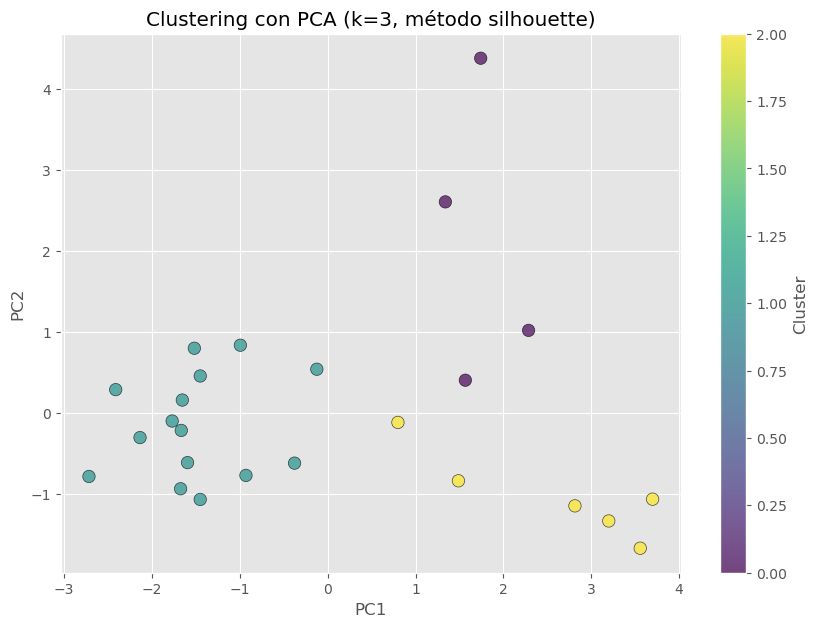

           Country  Cluster
12           Italy        0
16        Portugal        0
18           Spain        0
9           Greece        0
4   Czechoslovakia        1
5          Denmark        1
6        E Germany        1
7          Finland        1
8           France        1
2          Belgium        1
21              UK        1
11         Ireland        1
23       W Germany        1
13     Netherlands        1
14          Norway        1
15          Poland        1
1          Austria        1
20     Switzerland        1
19          Sweden        1
22            USSR        2


In [753]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Probar varios k y elegir el mejor según silhouette
silhouette_scores = {}
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"✅ Mejor número de clusters según silhouette: k={best_k}, score={silhouette_scores[best_k]:.3f}")

# 4. Ejecutar KMeans con el mejor k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
food_data["Cluster"] = clusters

# 5. Reducir con PCA a 2D para visualizar
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 6. Graficar clusters en PCA
plt.figure(figsize=(10,7))
scatter = plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap="viridis", s=80, alpha=0.7, edgecolors="k")
plt.title(f"Clustering con PCA (k={best_k}, método silhouette)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(scatter, label="Cluster")
plt.show()

# 7. Mostrar países asignados a clusters
print(food_data[["Country", "Cluster"]].sort_values("Cluster").head(20))

Qué hace este código:

- Escala los datos para que todas las proteínas tengan la misma importancia.
- Usa el método del codo para sugerir cuántos clústeres elegir.
- Aplica K-Means con 4 clústeres (puedes cambiarlo según lo que veas en el gráfico del codo).
- Visualiza los clústeres en 2D usando PCA.
- Muestra qué países quedaron en cada clúster.

Ahora que ya tenemos los clusters óptimos con el método Silhouette, podemos hacer un análisis interpretativo viendo el promedio de consumo de proteínas por cluster.

Esto nos ayuda a darle “significado” a cada grupo (ejemplo: países con alto consumo de carne, países con dieta basada en pescado, etc.).

In [756]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Determinar el mejor número de clusters según silhouette
silhouette_scores = {}
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"✅ Mejor número de clusters según silhouette: k={best_k}, score={silhouette_scores[best_k]:.3f}")

# 4. Ejecutar clustering final con el mejor k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
food_data["Cluster"] = kmeans.fit_predict(X_scaled)

# 5. Tabla con el promedio de consumo de proteínas por cluster
cluster_means = food_data.groupby("Cluster").mean(numeric_only=True)

print("\n📊 Promedio de consumo de proteínas por cluster:\n")
print(cluster_means)

# 6. Opcional: exportar tabla a CSV
cluster_means.to_csv("cluster_means_protein.csv")

✅ Mejor número de clusters según silhouette: k=3, score=0.335

📊 Promedio de consumo de proteínas por cluster:

           RedMeat   WhiteMeat      Eggs       Milk      Fish    Cereals  \
Cluster                                                                    
0         8.125000    3.800000  2.475000  11.200000  7.625000  33.675000   
1        11.340000    9.766667  3.580000  21.260000  4.686667  25.553333   
2         7.183333    5.950000  1.633333  10.683333  1.050000  48.033333   

           Starch      Nuts    Fr&Veg  
Cluster                                
0        3.975000  5.675000  7.075000  
1        4.853333  1.673333  3.740000  
2        3.033333  4.833333  3.166667  


- Cluster 0 → países con alto consumo de pescado.
- Cluster 1 → países con alto consumo de carne roja y leche.
- Cluster 2 → países con dieta más balanceada.

Mejor número de clusters según silhouette: k=3, score=0.335


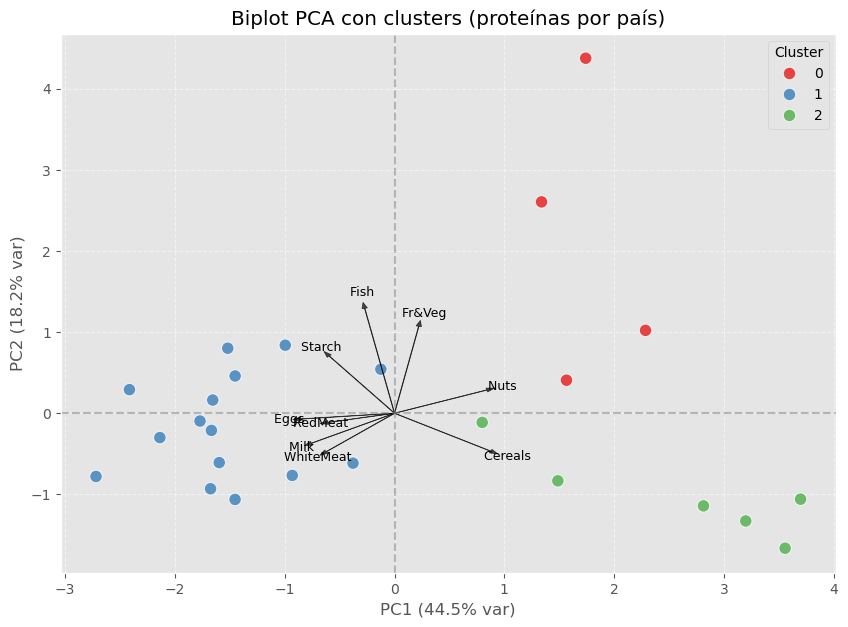

In [147]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos (quitamos columna no numérica)
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Determinar el mejor número de clusters según silhouette
silhouette_scores = {}
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"Mejor número de clusters según silhouette: k={best_k}, score={silhouette_scores[best_k]:.3f}")

# 4. Ejecutar clustering final
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
food_data["Cluster"] = kmeans.fit_predict(X_scaled)

# 5. PCA con 2 componentes
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

food_data["PC1"] = X_pca[:,0]
food_data["PC2"] = X_pca[:,1]

# 6. Biplot con clusters + cargas de variables
plt.figure(figsize=(10,7))

# Graficar países coloreados por cluster
sns.scatterplot(
    x="PC1", y="PC2",
    hue="Cluster", data=food_data,
    palette="Set1", s=80, alpha=0.8
)

# Dibujar vectores de las variables originales
loadings = pca.components_.T * 2  # escalamos vectores para visualización
for i, var in enumerate(X.columns):
    plt.arrow(0, 0, loadings[i,0], loadings[i,1],
              color="black", alpha=0.7, width=0.005, head_width=0.05)
    plt.text(loadings[i,0]*1.15, loadings[i,1]*1.15,
             var, color="black", ha="center", va="center", fontsize=9)

plt.title("Biplot PCA con clusters (proteínas por país)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.axhline(0, color="gray", linestyle="--", alpha=0.5)
plt.axvline(0, color="gray", linestyle="--", alpha=0.5)
plt.show()

Puntos: cada país, coloreado según su cluster.
- Ejes PC1 y PC2: las principales direcciones de variación en el consumo de proteínas.
- Flechas (vectores): representan los alimentos (carne roja, pescado, leche, etc.) y hacia dónde empujan la varianza.
- Si un cluster está hacia la dirección de la flecha de “Fish”, significa que ese grupo de países consume mucho pescado.
- Si está hacia “RedMeat”, son países con dieta basada en carne roja.

✅ Mejor número de clusters según silhouette: k=3, score=0.335


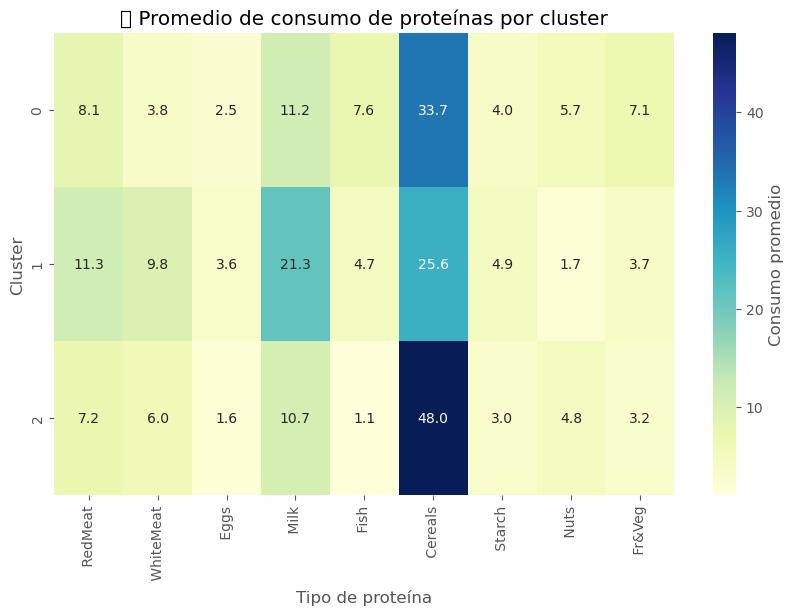

In [765]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Determinar el mejor número de clusters según silhouette
silhouette_scores = {}
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"✅ Mejor número de clusters según silhouette: k={best_k}, score={silhouette_scores[best_k]:.3f}")

# 4. Ejecutar clustering final con el mejor k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
food_data["Cluster"] = kmeans.fit_predict(X_scaled)

# 5. Tabla con promedio de consumo por cluster
cluster_means = food_data.groupby("Cluster").mean(numeric_only=True)

# 6. Heatmap de perfiles de consumo
plt.figure(figsize=(10,6))
sns.heatmap(cluster_means, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Consumo promedio'})
plt.title("📊 Promedio de consumo de proteínas por cluster")
plt.xlabel("Tipo de proteína")
plt.ylabel("Cluster")
plt.show()

Un heatmap donde cada fila es un cluster y cada columna un tipo de proteína.
- Los colores indican el nivel relativo de consumo promedio (más oscuro = mayor consumo).
- Te permite ver patrones claros, por ejemplo:
- Un cluster puede tener alto consumo de pescado y bajo de carne roja.
- Otro cluster puede tener alto consumo de leche y huevos.

Guía práctica
1. Datos numéricos en un espacio continuo
- Distancia Euclídea → estándar, funciona bien si todas las variables están en la misma escala.
- Distancia Manhattan (L1) → más robusta a outliers que la euclídea.
- Distancia Mahalanobis → recomendable si las variables están correlacionadas o tienen escalas muy diferentes (considera la covarianza).
- Consejo: si las variables están en distintas escalas, normaliza antes (z-score o min-max).

####  Aplicando Cluster jerarquic.  Qué hace este código a continuacion?
- Estandariza las variables de consumo.
- Calcula el dendrograma con distintos criterios de enlace:
- single: vecinos más cercanos.
- complete: vecinos más lejanos.
- average: promedio de distancias.
- ward: minimiza la varianza dentro de los clusters.
- Así puedes comparar cómo cambia la forma de los clusters dependiendo del método.

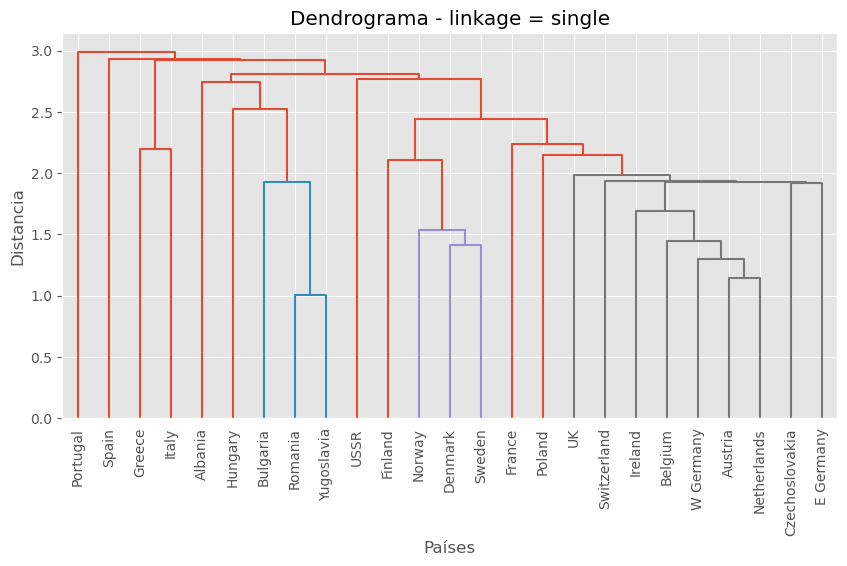

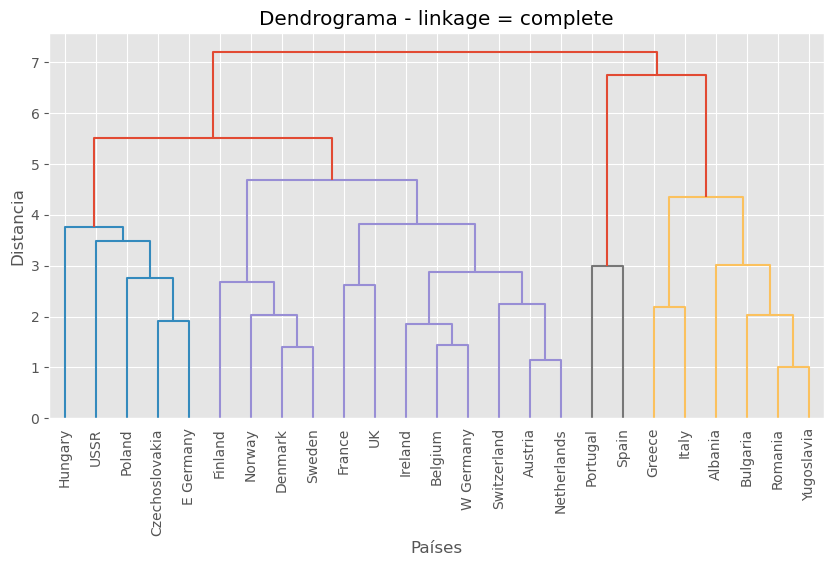

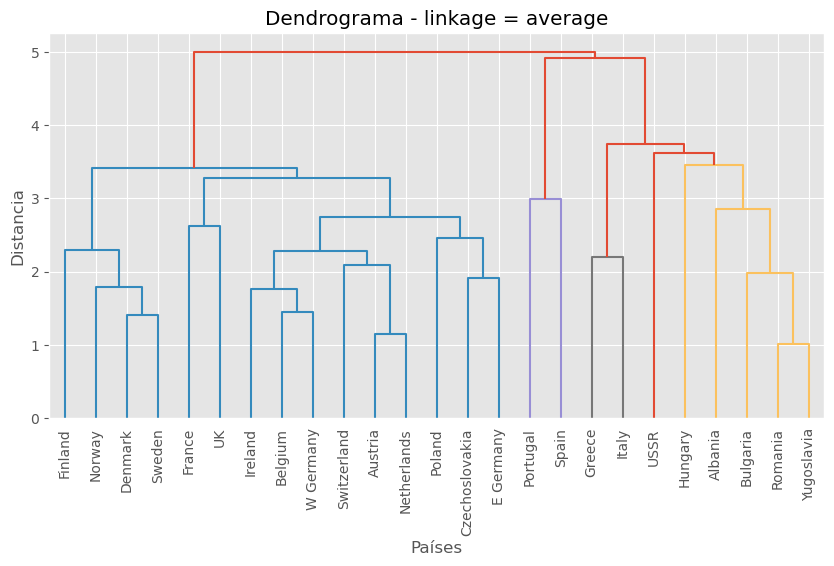

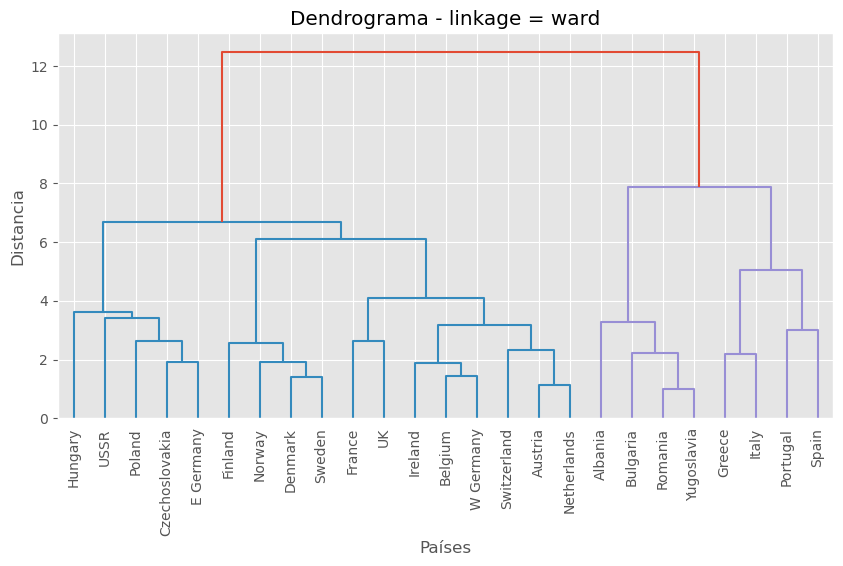

In [154]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

# ==============================
# 1. Cargar datos
# ==============================
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# Estandarizar variables numéricas
X = food_data.drop(columns=["Country"])
X_scaled = StandardScaler().fit_transform(X)

# ==============================
# 2. Función para graficar dendrograma
# ==============================
def plot_dendrogram(X, method):
    Z = linkage(X, method=method)
    plt.figure(figsize=(10, 5))
    dendrogram(Z, labels=food_data["Country"].values, leaf_rotation=90)
    plt.title(f"Dendrograma - linkage = {method}")
    plt.xlabel("Países")
    plt.ylabel("Distancia")
    plt.show()

# ==============================
# 3. Dibujar con distintos métodos
# ==============================
for method in ["single", "complete", "average", "ward"]:
    plot_dendrogram(X_scaled, method)

Qué hace el código:
- Dibuja el dendrograma con línea roja de corte.
- Usa fcluster para asignar países a clusters.
- Imprime en tabla los países y el cluster correspondiente.

#### DBSCAN

In [156]:
import pandas as pd

home_data = pd.read_csv('housing.csv', usecols = ['longitude', 'latitude', 'median_house_value'])
home_data.head()

,longitude,latitude,median_house_value
0,-122.23,37.88,452600.0
1,-122.22,37.86,358500.0
2,-122.24,37.85,352100.0
3,-122.25,37.85,341300.0
4,-122.25,37.85,342200.0


Explicación rápida:
- eps: radio de vecindad. Si es muy pequeño, tendrás muchos puntos como -1 (outliers). Si es grande, clusters se fusionan.
- min_samples: número mínimo de vecinos para formar un cluster.
- Cluster -1: significa ruido (puntos que DBSCAN no clasificó en ningún cluster).

Explicación:
- Visualización: ves cómo cambian los clusters al variar eps.
- Silhouette Score: mide la calidad de los clusters (1 es ideal, 0 significa clusters superpuestos, valores negativos son malos).
- Si DBSCAN detecta solo ruido o un único cluster, no se calcula el Silhouette (se queda en None).

Aquí tienes el código completo que además de aplicar DBSCAN y calcular los Silhouette Scores, dibuja la evolución del Silhouette en función de eps para identificar el mejor valor:

El k-dist plot es un método clásico para estimar el parámetro eps en DBSCAN.
La idea es:
- Calcular la distancia al k-ésimo vecino más cercano (normalmente k = min_samples, por ejemplo 10).
- Ordenar esas distancias.
- Buscar el "codo" del gráfico → allí suele estar el valor adecuado para eps.
- Aquí te dejo el código adaptado a tu base housing.csv:

Cómo usar el gráfico:
- El gráfico es creciente y en algún punto verás un codo (elbow).
- Ese valor en el eje Y es un buen candidato para eps.
- Ejemplo: si el codo aparece cerca de 0.8, puedes probar eps=0.8 en DBSCAN.

Entonces armemos un pipeline completo que:
- Calcula el eps sugerido a partir del k-dist plot.
- Ejecuta DBSCAN con ese eps.
- Evalúa con el Silhouette Score.
- Grafica los clusters encontrados (en 2D usando longitude y latitude).

In [ ]:
from google.colab import files

# Abrir ventana para seleccionar el archivo
uploaded = files.upload()

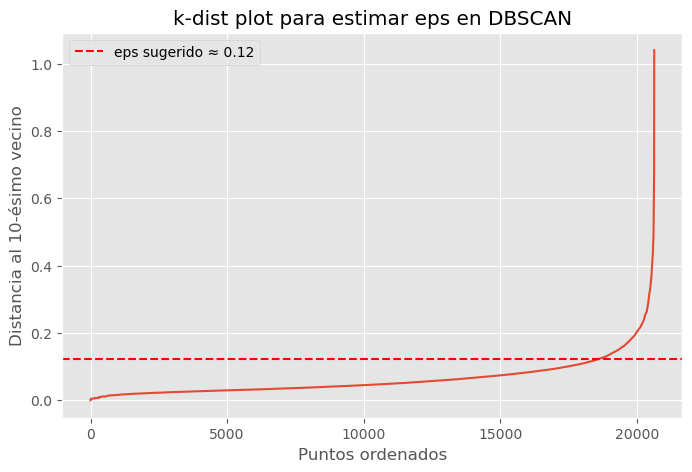

 eps sugerido: 0.121


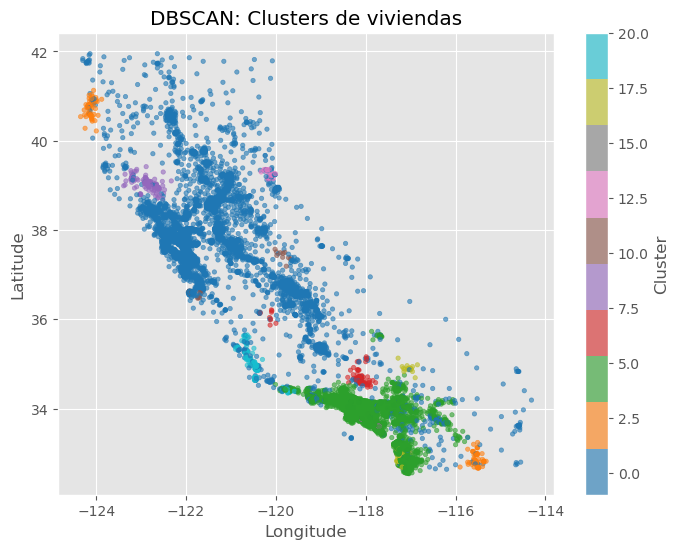

In [164]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# ==============================
# 1. Cargar datos
# ==============================
home_data = pd.read_csv('housing.csv', usecols=['longitude', 'latitude', 'median_house_value'])

# Variables para clustering
X = home_data[['longitude', 'latitude', 'median_house_value']]

# Escalar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==============================
# 2. Estimar eps con k-dist plot
# ==============================
k = 10  # valor típico igual a min_samples
neighbors = NearestNeighbors(n_neighbors=k)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

k_distances = np.sort(distances[:, k-1])  # distancias al k-ésimo vecino
eps_sugerido = np.percentile(k_distances, 90)  # heurística (puedes ajustar)

# Graficar k-dist plot
plt.figure(figsize=(8,5))
plt.plot(k_distances)
plt.axhline(y=eps_sugerido, color="r", linestyle="--", label=f"eps sugerido ≈ {eps_sugerido:.2f}")
plt.ylabel(f"Distancia al {k}-ésimo vecino")
plt.xlabel("Puntos ordenados")
plt.title("k-dist plot para estimar eps en DBSCAN")
plt.legend()
plt.grid(True)
plt.show()

print(f" eps sugerido: {eps_sugerido:.3f}")

# ==============================
# 3. Ejecutar DBSCAN
# ==============================
dbscan = DBSCAN(eps=eps_sugerido, min_samples=k)
clusters = dbscan.fit_predict(X_scaled)

home_data['Cluster'] = clusters


# ==============================
# 4. Graficar clusters en mapa
# ==============================
plt.figure(figsize=(8,6))
plt.scatter(
    home_data['longitude'], home_data['latitude'],
    c=home_data['Cluster'], cmap="tab10", s=10, alpha=0.6
)
plt.colorbar(label="Cluster")
plt.title("DBSCAN: Clusters de viviendas")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

A continuación un mapa comparativo donde se distinguen:
Los clusters encontrados por DBSCAN (colores distintos).
El ruido (-1) en color gris oscuro.

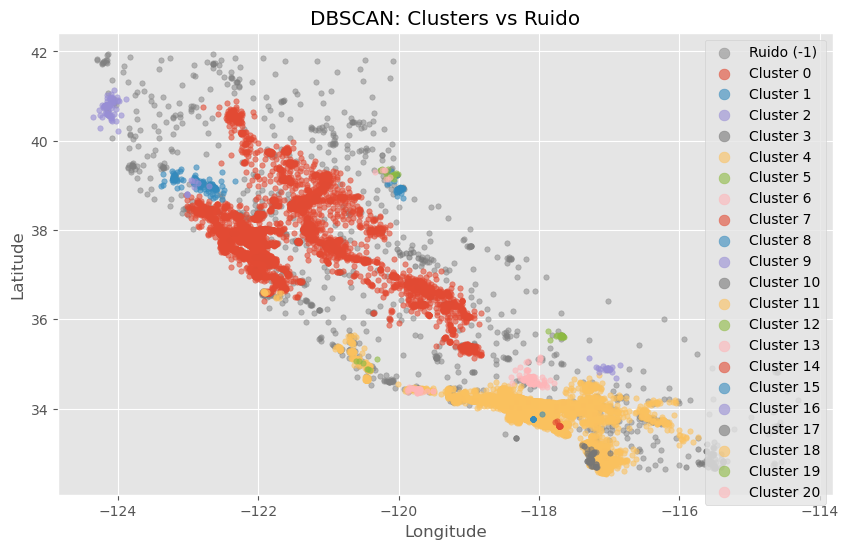

In [167]:
import matplotlib.pyplot as plt

# ==============================
# 6. Graficar clusters y ruido
# ==============================
plt.figure(figsize=(10,6))

# Puntos de ruido
plt.scatter(
    home_data.loc[home_data['Cluster'] == -1, 'longitude'],
    home_data.loc[home_data['Cluster'] == -1, 'latitude'],
    c="gray", s=15, alpha=0.5, label="Ruido (-1)"
)

# Puntos de cada cluster
for c in set(home_data['Cluster']):
    if c != -1:
        plt.scatter(
            home_data.loc[home_data['Cluster'] == c, 'longitude'],
            home_data.loc[home_data['Cluster'] == c, 'latitude'],
            s=15, alpha=0.6, label=f"Cluster {c}"
        )

plt.title("DBSCAN: Clusters vs Ruido")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(markerscale=2)
plt.show()

Esto te genero un mapa comparativo donde:
- El ruido aparece en gris.
- Los clusters en colores distintos.
- La leyenda indica qué es ruido y qué cluster corresponde.

Esto te genera un mapa comparativo donde:
El ruido aparece en gris.
Los clusters en colores distintos.
La leyenda indica qué es ruido y qué cluster corresponde.

Número de observaciones por cluster:

Cluster
-1      1163
 0      8074
 1        46
 2       100
 3        90
 4     10524
 5        19
 6       102
 7        10
 8       113
 9        10
 10       10
 11       14
 12       17
 13        7
 14       14
 15       11
 16       25
 17       52
 18      194
 19        7
 20       38
Name: count, dtype: int64

Tabla resumen:
    Cluster  Cantidad
0        -1      1163
1         0      8074
2         1        46
3         2       100
4         3        90
5         4     10524
6         5        19
7         6       102
8         7        10
9         8       113
10        9        10
11       10        10
12       11        14
13       12        17
14       13         7
15       14        14
16       15        11
17       16        25
18       17        52
19       18       194
20       19         7
21       20        38


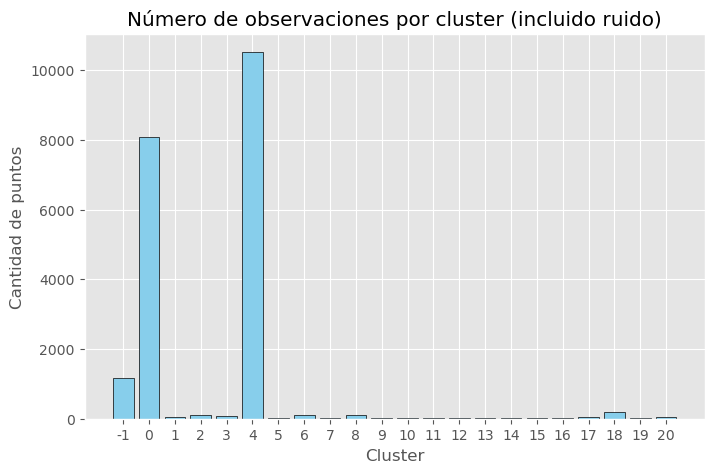

In [169]:
# ==============================
# 7. Resumen de observaciones por cluster
# ==============================
resumen_clusters = home_data['Cluster'].value_counts().sort_index()
print("Número de observaciones por cluster:\n")
print(resumen_clusters)

# Convertir en DataFrame para más claridad
resumen_df = resumen_clusters.reset_index()
resumen_df.columns = ['Cluster', 'Cantidad']

import pandas as pd
import matplotlib.pyplot as plt

# Mostrar tabla
print("\nTabla resumen:")
print(resumen_df)

# ==============================
# 8. Gráfico de barras
# ==============================
plt.figure(figsize=(8,5))
plt.bar(resumen_df['Cluster'].astype(str), resumen_df['Cantidad'], color="skyblue", edgecolor="black")
plt.title("Número de observaciones por cluster (incluido ruido)")
plt.xlabel("Cluster")
plt.ylabel("Cantidad de puntos")
plt.show()

A continuación un mapa de calor

Promedio de median_house_value por cluster:

    Cluster  median_house_value
0        -1       183263.208083
1         0       195722.930518
2         1       108452.173913
3         2        84591.000000
4         3        75458.888889
5         4       222568.668377
6         5        90042.105263
7         6       124927.450980
8         7        59660.000000
9         8        96598.230088
10        9       137380.000000
11       10       110820.000000
12       11       285607.142857
13       12       152194.117647
14       13       177871.428571
15       14        76028.571429
16       15        59954.545455
17       16        67940.000000
18       17       498477.750000
19       18       170637.113402
20       19       274457.142857
21       20       339568.421053


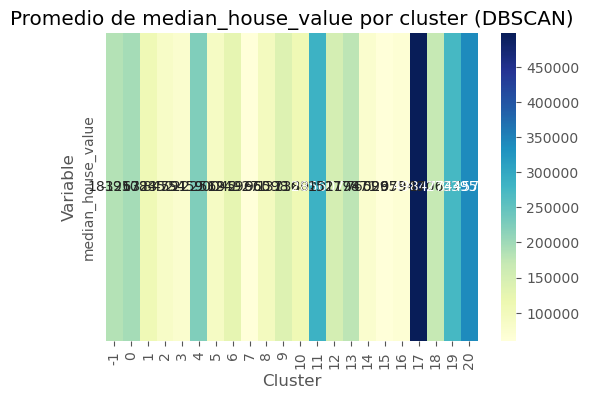

In [171]:
import seaborn as sns
import matplotlib.pyplot as plt

# ==============================
# 9. Promedio de median_house_value por cluster
# ==============================
cluster_means = home_data.groupby("Cluster")["median_house_value"].mean().reset_index()

print("Promedio de median_house_value por cluster:\n")
print(cluster_means)

# ==============================
# 10. Heatmap
# ==============================
plt.figure(figsize=(6,4))
sns.heatmap(cluster_means.set_index("Cluster").T, annot=True, cmap="YlGnBu", fmt=".0f")
plt.title("Promedio de median_house_value por cluster (DBSCAN)")
plt.ylabel("Variable")
plt.xlabel("Cluster")
plt.show()

Este heatmap te mostrará:
- Columnas = clusters (incluido -1 = ruido)
- Valores = promedio de median_house_value en cada cluster
- Así puedes ver rápidamente qué grupos tienen viviendas más caras o más baratas.

Vamos a hacer un mapa geográfico de los clusters detectados por DBSCAN usando las columnas longitude y latitude.

A continuacion un mapa con un coloreado por median_house_value (en lugar de cluster), para comparar cómo se relaciona el precio de las viviendas con los grupos detectados?

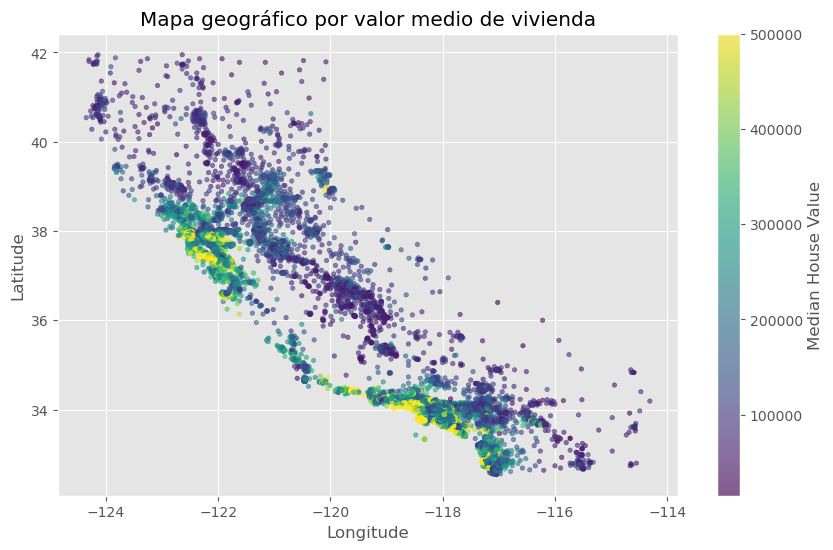

In [841]:
import matplotlib.pyplot as plt

# ==============================
# 12. Mapa geográfico por valor medio de vivienda
# ==============================
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    home_data["longitude"], 
    home_data["latitude"], 
    c=home_data["median_house_value"], 
    cmap="viridis", 
    s=10, 
    alpha=0.6
)

plt.colorbar(scatter, label="Median House Value")
plt.title("Mapa geográfico por valor medio de vivienda")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

Un mapa en escala de colores (viridis) donde los tonos representan el valor medio de las casas.
Puedes comparar este gráfico con el de los clusters DBSCAN y notar si el algoritmo separó bien las zonas de alto y bajo valor.

Vamos a ponerle un mapa base real para que los clusters de DBSCAN se ubiquen sobre un mapa geográfico de California.
Lo más sencillo es usar contextily con coordenadas en proyección métrica (Web Mercator: EPSG:3857).
Te paso el código paso a paso:

en este mapa lo puedes mover con el mouse, hacer zoom in/out y explorar dónde están los clusters que encontró DBSCAN.
🔹 Los puntos negros (-1) son considerados ruido (outliers) por el algoritmo.

In [176]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
import folium

# ==============================
# 1. Cargar datos
# ==============================
home_data = pd.read_csv("housing.csv", usecols=["longitude", "latitude", "median_house_value"])

# ==============================
# 2. Escalar coordenadas
# ==============================
scaler = StandardScaler()
X = scaler.fit_transform(home_data[['longitude', 'latitude']])

# ==============================
# 3. Ajustar DBSCAN
# ==============================
dbscan = DBSCAN(eps=0.3, min_samples=50)
clusters = dbscan.fit_predict(X)
home_data["cluster"] = clusters

# ==============================
# 4. Crear mapa base
# ==============================
m = folium.Map(location=[37, -119], zoom_start=6, tiles="CartoDB positron")

# ==============================
# 5. Crear capas por cluster
# ==============================
unique_clusters = sorted(home_data["cluster"].unique())
colors = [
    "red", "blue", "green", "purple", "orange", "brown", 
    "pink", "cadetblue", "darkgreen", "lightred"
]

for idx, cluster_id in enumerate(unique_clusters):
    if cluster_id == -1:
        layer_name = "Ruido (-1)"
        color = "black"
    else:
        layer_name = f"Cluster {cluster_id}"
        color = colors[idx % len(colors)]

    fg = folium.FeatureGroup(name=layer_name)

    cluster_points = home_data[home_data["cluster"] == cluster_id]

    for _, row in cluster_points.iterrows():
        popup_text = f"""
        Cluster: {cluster_id}<br>
        Valor medio casa: ${row['median_house_value']:,.0f}<br>
        Lat: {row['latitude']:.4f}, Lon: {row['longitude']:.4f}
        """
        folium.CircleMarker(
            location=[row["latitude"], row["longitude"]],
            radius=2,
            color=color,
            fill=True,
            fill_opacity=0.6,
            popup=folium.Popup(popup_text, max_width=250)
        ).add_to(fg)

    fg.add_to(m)

# ==============================
# 6. Control de capas
# ==============================
folium.LayerControl().add_to(m)

# ==============================
# 7. Mostrar mapa
# ==============================
m

Ahora al hacer click en un punto, verás:
El número de cluster al que pertenece
El valor medio de la casa (median_house_value)
Las coordenadas (lat, lon)